# Exploratory Data Analysis on Retail Transaction Data

**NextHikes IT Solutions**

**Objective:** To explore a retail dataset of 100,000 orders (18 columns) and find out how the columns behave on their own, how they are related to each other, and whether there is anything unusual in the data. The work is done in the following order:

1. Load and understand the data
2. Clean the data and make some new columns
3. Univariate analysis (one column at a time)
4. Outliers and capping
5. Bivariate analysis (two columns together)
6. Multivariate analysis (three or more columns together)
7. Extra analysis (time, city, products, discounts)
8. Final findings and conclusion

## 1. Import Libraries and Load the Data

**Objective:** Import the libraries, load the csv file and have a first look at it.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# folder where the charts will be saved
os.makedirs("outputs/figures", exist_ok=True)

In [3]:
retail_data_raw = pd.read_csv("data/Original_dataset.csv")
print("Rows:", retail_data_raw.shape[0], "| Columns:", retail_data_raw.shape[1])
retail_data_raw.head()

Rows: 100000 | Columns: 18


,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
0,C10000,56,Male,Hyderabad,Telangana,New,O50000,2025-05-10,Health,Protein Powder,38658,3,7,"107,855.82",Debit Card,Standard,5,No
1,C10001,36,Male,Pune,Maharashtra,Premium,O50001,2023-11-27,Electronics,Smartphone,22462,4,20,"71,878.40",Cash on Delivery,Standard,4,Yes
2,C10002,20,Male,Kolkata,West Bengal,New,O50002,2025-02-08,Fashion,Women Dress,56601,2,27,"82,637.46",Credit Card,Standard,5,No
3,C10003,39,Female,Jaipur,Rajasthan,New,O50003,2024-04-19,Beauty,Perfume,26158,3,9,"71,411.34",UPI,Standard,3,No
4,C10004,20,Male,Chennai,Tamil Nadu,Premium,O50004,2024-10-08,Beauty,Shampoo,31240,1,6,"29,365.60",UPI,Standard,2,No


In [4]:
retail_data_raw.tail()

,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
99995,C109995,29,Female,Pune,Maharashtra,Regular,O149995,2024-06-11,Health,Supplements,49293,1,11,"43,870.77",Debit Card,Standard,9,No
99996,C109996,28,Male,Mumbai,Maharashtra,Premium,O149996,2024-04-27,Fashion,Men T-Shirt,5722,2,22,"8,926.32",Cash on Delivery,Express,1,No
99997,C109997,44,Female,Jaipur,Rajasthan,Premium,O149997,2024-04-14,Grocery,Snacks,6311,4,11,"22,467.16",Cash on Delivery,Express,9,No
99998,C109998,45,Male,Jaipur,Rajasthan,Premium,O149998,2024-09-08,Beauty,Shampoo,46888,1,28,"33,759.36",Debit Card,Standard,1,No
99999,C109999,19,Male,Kolkata,West Bengal,New,O149999,2025-11-15,Health,Supplements,37361,3,3,"108,720.51",Credit Card,Standard,2,No


In [5]:
retail_data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          100000 non-null  str    
 1   age                  100000 non-null  int64  
 2   gender               100000 non-null  str    
 3   city                 100000 non-null  str    
 4   state                100000 non-null  str    
 5   customer_segment     100000 non-null  str    
 6   order_id             100000 non-null  str    
 7   order_date           100000 non-null  str    
 8   product_category     100000 non-null  str    
 9   product_subcategory  100000 non-null  str    
 10  product_price        100000 non-null  int64  
 11  quantity             100000 non-null  int64  
 12  discount_percentage  100000 non-null  int64  
 13  final_price          100000 non-null  float64
 14  payment_method       100000 non-null  str    
 15  shipping_type        100000 n

In [6]:
retail_data_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"100,000.00",NaN,NaN,NaN,41.56,13.85,18.00,30.00,42.00,54.00,65.00
gender,100000,2,Male,50111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,100000,10,Hyderabad,10150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,100000,9,Maharashtra,19952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,100000,3,New,33488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,100000,100000,O50000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,100000,1095,2023-04-12,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,100000,6,Health,16858,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_subcategory,100000,21,Protein Powder,5668,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretation:**

* The data has 100,000 rows and 18 columns. `info()` shows 100,000 values in every column, so nothing looks missing at first sight.
* 12 columns are text, 5 are whole numbers and only `final_price` has decimals. `order_date` is stored as text, so it has to be converted later.
* `customer_id` and `order_id` both have 100,000 different values, so every row is a different customer and a different order.
* From `describe()`: age is from 18 to 65, price from 500 to 59,998, quantity from 1 to 4, discount from 0 to 30 and delivery days from 1 to 10. For `final_price` the mean (64,166) is much higher than the median (49,752), so it may be skewed. I will check this in section 4.
* The orders are spread over 1,095 different dates.

## 2. Understanding the Columns

**Objective:** Divide the columns into types (ID, date, numerical, categorical) so that we can use the right charts and methods for each.

| Column | Meaning |
|---|---|
| customer_id, order_id | ID of the customer and of the order |
| age, gender | Customer age and gender |
| city, state | Where the customer lives |
| customer_segment | New, Regular or Premium customer |
| order_date | Date of the order |
| product_category, product_subcategory | What was bought |
| product_price | Price of one unit |
| quantity | Number of units in the order |
| discount_percentage | Discount given (%) |
| final_price | Amount of the order after discount |
| payment_method, shipping_type | How the customer paid and how it was shipped |
| delivery_days | Days taken to deliver |
| return_status | Whether the order was returned (Yes/No) |

In [7]:
id_cols = ["customer_id", "order_id"]
date_cols = ["order_date"]
num_cols = ["age", "product_price", "quantity", "discount_percentage", "final_price", "delivery_days"]
cat_cols = ["gender", "city", "state", "customer_segment", "product_category",
            "product_subcategory", "payment_method", "shipping_type", "return_status"]

print("ID columns:", len(id_cols))
print("Date columns:", len(date_cols))
print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))

# number of different values in each column
retail_data_raw.nunique().to_frame("unique_values")

ID columns: 2
Date columns: 1
Numerical columns: 6
Categorical columns: 9


,unique_values
customer_id,100000
age,48
gender,2
city,10
state,9
customer_segment,3
order_id,100000
order_date,1095
product_category,6
product_subcategory,21


**Interpretation:**

* The 18 columns are 2 ID columns, 1 date column, 6 numerical and 9 categorical columns. The ID columns are only labels, so they are not used in the statistics.
* `quantity` (4 values), `delivery_days` (10 values) and `discount_percentage` (31 values) are numbers, but they take only a few whole values. I kept them as numerical but at some places they are treated like groups.
* Every `customer_id` appears only once, which means each customer placed just one order. So we cannot study repeat customers from this data.
* There are 6 categories with 21 subcategories, 10 cities and 9 states.

## 3. Data Cleaning

**Objective:** Check the data for problems (wrong column names, extra spaces, missing values, duplicates, wrong data types, impossible values) and fix them. After that we add a few new columns which will be useful in the analysis.

### 3.1 Column names and extra spaces

In [8]:
# work on a copy so the original data stays untouched
retail_data = retail_data_raw.copy()

print("Column names with spaces:", [c for c in retail_data.columns if " " in c])
print("Column names with special characters:", [c for c in retail_data.columns if not c.replace("_", "").isalnum()])
print("Duplicate column names:", retail_data.columns.duplicated().sum())

# remove spaces around the names and make them lowercase (just to be safe)
retail_data.columns = retail_data.columns.str.strip().str.lower()

# extra spaces inside the text columns
for col in id_cols + cat_cols:
    extra_spaces = (retail_data[col] != retail_data[col].str.strip()).sum()
    print(col, "-> values with extra spaces:", extra_spaces)
    retail_data[col] = retail_data[col].str.strip()

Column names with spaces: []
Column names with special characters: []
Duplicate column names: 0
customer_id -> values with extra spaces: 0
order_id -> values with extra spaces: 0
gender -> values with extra spaces: 0
city -> values with extra spaces: 0
state -> values with extra spaces: 0
customer_segment -> values with extra spaces: 0
product_category -> values with extra spaces: 0
product_subcategory -> values with extra spaces: 0
payment_method -> values with extra spaces: 0
shipping_type -> values with extra spaces: 0
return_status -> values with extra spaces: 0


**Interpretation:**

The column names are already clean. There are no spaces, no special characters and no duplicate names, and removing the spaces and making them lowercase changed nothing. None of the text columns had extra spaces either.

### 3.2 Spelling and special characters in the categories

Checking the values of each small categorical column to see if the same thing is written in two different ways (like "male" and "Male").

In [9]:
for col in ["gender", "customer_segment", "product_category", "payment_method", "shipping_type", "return_status"]:
    print(col, "->", list(retail_data[col].unique()))

print()
print("Cities:", sorted(retail_data["city"].unique()))
print("States:", sorted(retail_data["state"].unique()))

gender -> ['Male', 'Female']
customer_segment -> ['New', 'Premium', 'Regular']
product_category -> ['Health', 'Electronics', 'Fashion', 'Beauty', 'Grocery', 'Home & Kitchen']
payment_method -> ['Debit Card', 'Cash on Delivery', 'Credit Card', 'UPI']
shipping_type -> ['Standard', 'Express']
return_status -> ['No', 'Yes']

Cities: ['Ahmedabad', 'Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Mumbai', 'Noida', 'Pune']
States: ['Delhi', 'Gujarat', 'Karnataka', 'Maharashtra', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Uttar Pradesh', 'West Bengal']


**Interpretation:**

Every category is written in only one way, so there are no spelling mistakes or mixed capital and small letters. The "&" in Home & Kitchen and the "-" in Men T-Shirt are part of the real names. There are 10 cities and 9 states, and Mumbai and Pune both belong to Maharashtra.

### 3.3 Missing values and duplicates

In [10]:
print("Total missing values in the whole data:", retail_data.isnull().sum().sum())
print("Fully duplicate rows:", retail_data.duplicated().sum())
print("Repeated order_id:", retail_data["order_id"].duplicated().sum())
print("Repeated customer_id:", retail_data["customer_id"].duplicated().sum())

# missing values per column
retail_data.isnull().sum().to_frame("missing_values").T

Total missing values in the whole data: 0
Fully duplicate rows: 0
Repeated order_id: 0
Repeated customer_id: 0


,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
missing_values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**Interpretation:**

There are no missing values, no duplicate rows and no repeated order_id or customer_id. So no rows had to be removed or filled and all 100,000 rows are used for the analysis.

### 3.4 Date column and sanity checks

The `order_date` column is stored as text, so it is converted to a proper date. After that I check if the values are sensible (age, discount, delivery days) and if `final_price` really is price x quantity after discount.

In [11]:
retail_data["order_date"] = pd.to_datetime(retail_data["order_date"])
print("First order:", retail_data["order_date"].min().date())
print("Last order :", retail_data["order_date"].max().date())
print()

# are the values in a sensible range?
print("Age:", retail_data["age"].min(), "to", retail_data["age"].max())
print("Product price:", retail_data["product_price"].min(), "to", retail_data["product_price"].max())
print("Quantity:", retail_data["quantity"].min(), "to", retail_data["quantity"].max())
print("Discount %:", retail_data["discount_percentage"].min(), "to", retail_data["discount_percentage"].max())
print("Delivery days:", retail_data["delivery_days"].min(), "to", retail_data["delivery_days"].max())
print()

# is final_price = price x quantity x (1 - discount)?
calculated_price = retail_data["product_price"] * retail_data["quantity"] * (1 - retail_data["discount_percentage"] / 100)
difference = (calculated_price - retail_data["final_price"]).abs()
print("Biggest difference between calculated and given final_price:", round(difference.max(), 3))
print("Rows where they do not match:", (difference > 0.01).sum())

# does each city belong to only one state, and each subcategory to only one category?
print("Cities with more than one state:", (retail_data.groupby("city")["state"].nunique() > 1).sum())
print("Subcategories with more than one category:", (retail_data.groupby("product_subcategory")["product_category"].nunique() > 1).sum())

First order: 2023-01-01
Last order : 2025-12-30

Age: 18 to 65
Product price: 500 to 59998
Quantity: 1 to 4
Discount %: 0 to 30
Delivery days: 1 to 10

Biggest difference between calculated and given final_price: 0.0
Rows where they do not match: 0
Cities with more than one state: 0
Subcategories with more than one category: 0


**Interpretation:**

* `order_date` was converted successfully. The orders are from 1 January 2023 to 30 December 2025, so about three years.
* All values are in a sensible range: age 18 to 65, price 500 to 59,998, quantity 1 to 4, discount 0 to 30% and delivery 1 to 10 days.
* `final_price` matches price x quantity x (1 - discount) in every row (0 rows do not match). This means `final_price` is a calculated column. So when it shows a strong relation with price, quantity and discount later, that is expected from the formula and is not a new finding.
* Every city belongs to only one state and every subcategory to only one category.

### 3.5 Creating new columns

New columns made from the existing ones: year, month, weekday, gross amount (before discount), discount amount, revenue per unit, a 0/1 return column, and groups (bins) for age, discount and delivery time.

In [12]:
retail_data["order_year"] = retail_data["order_date"].dt.year
retail_data["order_month"] = retail_data["order_date"].dt.month
retail_data["weekday"] = retail_data["order_date"].dt.day_name()

retail_data["gross_amount"] = retail_data["product_price"] * retail_data["quantity"]
retail_data["discount_amount"] = retail_data["gross_amount"] - retail_data["final_price"]
retail_data["revenue_per_unit"] = retail_data["final_price"] / retail_data["quantity"]
retail_data["is_return"] = (retail_data["return_status"] == "Yes").astype(int)

retail_data["age_group"] = pd.cut(retail_data["age"], bins=[17, 25, 35, 45, 55, 65],
                                  labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
retail_data["discount_band"] = pd.cut(retail_data["discount_percentage"], bins=[-1, 5, 10, 15, 20, 25, 30],
                                      labels=["0-5%", "6-10%", "11-15%", "16-20%", "21-25%", "26-30%"])
retail_data["delivery_speed"] = pd.cut(retail_data["delivery_days"], bins=[0, 3, 6, 10],
                                       labels=["Fast (1-3 days)", "Medium (4-6 days)", "Slow (7-10 days)"])

print("Shape now:", retail_data.shape)
print("Rows without an age group / discount band / delivery speed:",
      retail_data[["age_group", "discount_band", "delivery_speed"]].isnull().sum().sum())
retail_data[["order_date", "weekday", "gross_amount", "discount_amount", "revenue_per_unit",
             "is_return", "age_group", "discount_band", "delivery_speed"]].head()

Shape now: (100000, 28)
Rows without an age group / discount band / delivery speed: 0


,order_date,weekday,gross_amount,discount_amount,revenue_per_unit,is_return,age_group,discount_band,delivery_speed
0,2025-05-10,Saturday,115974,"8,118.18","35,951.94",0,56-65,6-10%,Medium (4-6 days)
1,2023-11-27,Monday,89848,"17,969.60","17,969.60",1,36-45,16-20%,Medium (4-6 days)
2,2025-02-08,Saturday,113202,"30,564.54","41,318.73",0,18-25,26-30%,Medium (4-6 days)
3,2024-04-19,Friday,78474,"7,062.66","23,803.78",0,36-45,6-10%,Fast (1-3 days)
4,2024-10-08,Tuesday,31240,"1,874.40","29,365.60",0,18-25,6-10%,Fast (1-3 days)


**Interpretation:**

10 new columns were added, so the data went from 18 to 28 columns (two more are added in section 6). Every row got an age group, discount band and delivery speed. One thing to remember is that the 0-5% discount band covers six values (0, 1, 2, 3, 4, 5) while the other bands cover five, so that band will have a few more orders.

## 4. Univariate Analysis: Numerical Columns

**Objective:** Look at each numerical column separately. We find the mean, median, standard deviation, minimum, maximum, skewness and kurtosis, and draw histograms (with KDE line) and boxplots.

Quick guide for reading skewness and kurtosis: skewness close to 0 means the data is balanced on both sides, a positive value means a long tail on the right. Kurtosis (excess) close to 0 means a normal bell-like shape, a negative value means a flat shape and a big positive value means very extreme values.

### 4.1 Summary table

In [13]:
summary = retail_data[num_cols].describe().T
summary["median"] = retail_data[num_cols].median()
summary["skewness"] = retail_data[num_cols].skew()
summary["kurtosis"] = retail_data[num_cols].kurt()
summary = summary[["mean", "median", "std", "min", "max", "skewness", "kurtosis"]]
summary

,mean,median,std,min,max,skewness,kurtosis
age,41.56,42.00,13.85,18.00,65.00,-0.00,-1.20
product_price,"30,164.53","30,148.00","17,139.68",500.00,"59,998.00",0.00,-1.20
quantity,2.50,3.00,1.12,1.00,4.00,-0.00,-1.36
discount_percentage,15.01,15.00,8.95,0.00,30.00,-0.00,-1.20
final_price,"64,165.72","49,752.39","49,969.28",357.00,"239,980.00",0.93,0.17
delivery_days,5.51,5.00,2.87,1.00,10.00,0.00,-1.22


### 4.2 Histograms with KDE

The black dashed line is the mean and the red dotted line is the median.

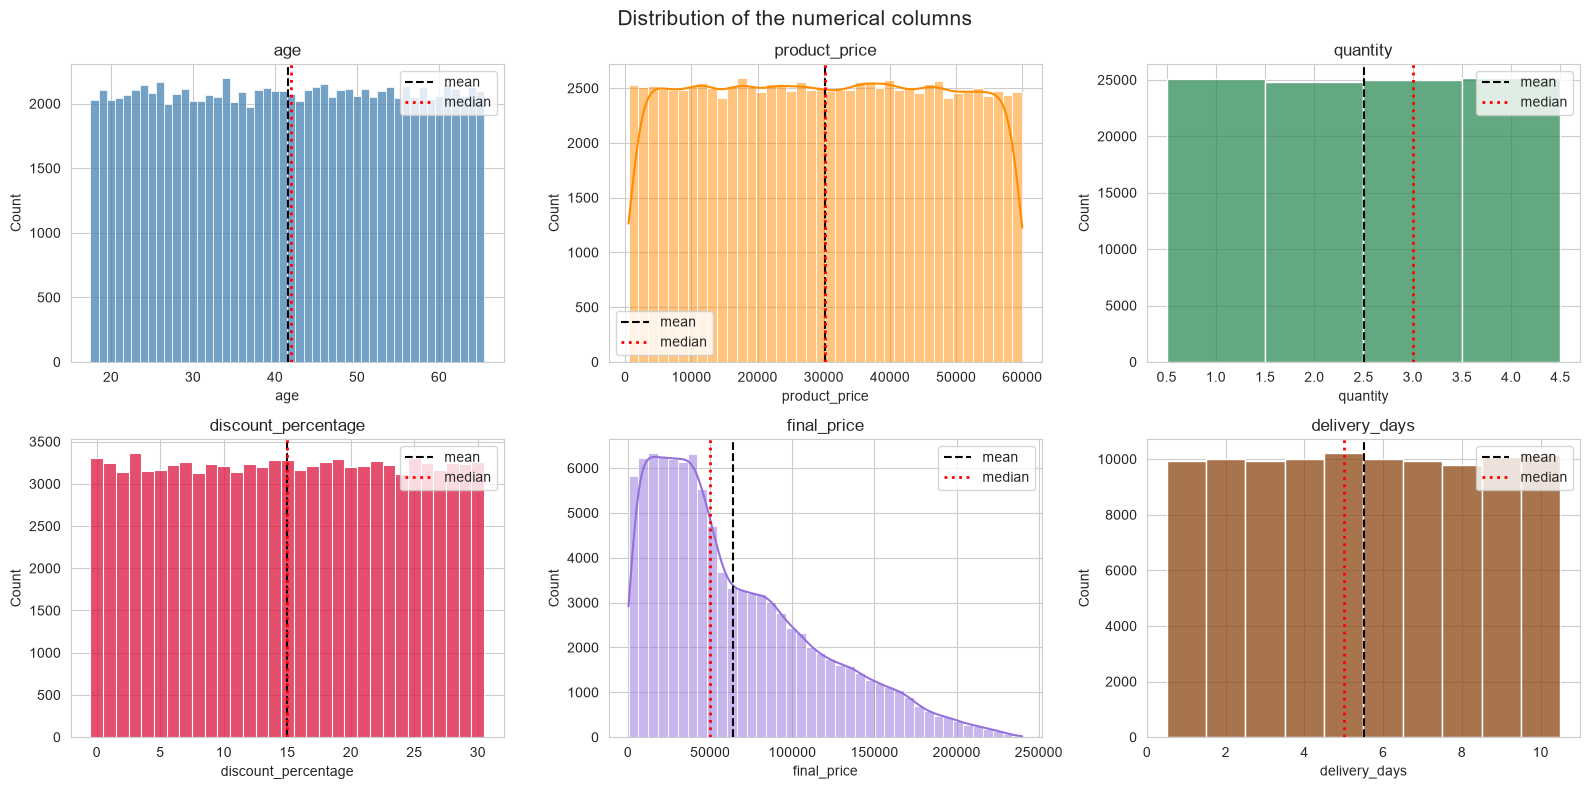

In [14]:
colors = ["steelblue", "darkorange", "seagreen", "crimson", "mediumpurple", "saddlebrown"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col, color in zip(axes.flatten(), num_cols, colors):
    if retail_data[col].nunique() < 60:
        # columns with only a few whole numbers: one bar for each value
        sns.histplot(retail_data[col], discrete=True, color=color, ax=ax)
    else:
        sns.histplot(retail_data[col], bins=40, kde=True, color=color, ax=ax)
    ax.axvline(retail_data[col].mean(), color="black", linestyle="--", label="mean")
    ax.axvline(retail_data[col].median(), color="red", linestyle=":", linewidth=2, label="median")
    ax.set_title(col)
    ax.legend()

plt.suptitle("Distribution of the numerical columns", fontsize=15)
plt.tight_layout()
plt.savefig("outputs/figures/01_histograms.png", bbox_inches="tight")
plt.show()

### 4.3 Boxplots

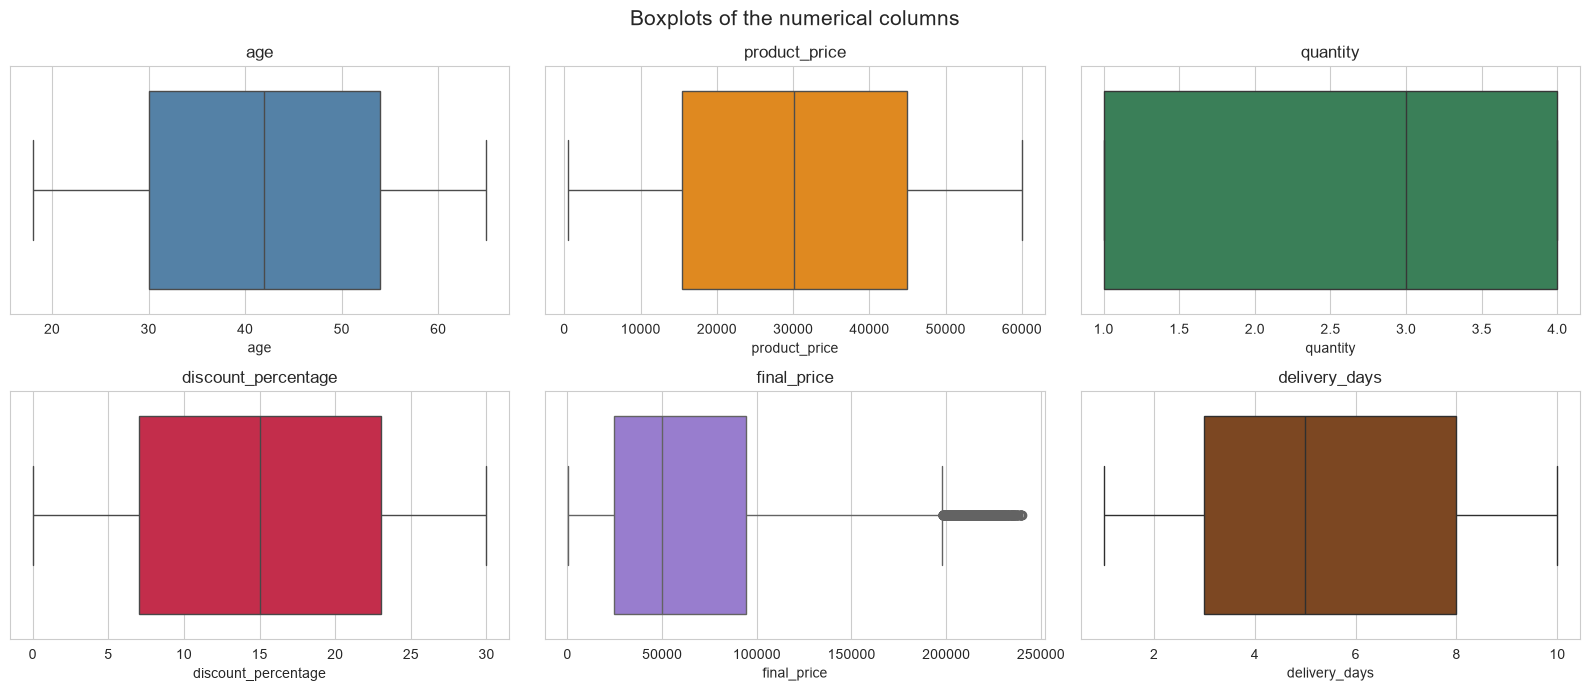

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col, color in zip(axes.flatten(), num_cols, colors):
    sns.boxplot(x=retail_data[col], color=color, ax=ax)
    ax.set_title(col)

plt.suptitle("Boxplots of the numerical columns", fontsize=15)
plt.tight_layout()
plt.savefig("outputs/figures/02_boxplots.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* Five columns (age, product_price, quantity, discount_percentage and delivery_days) have flat histograms. Their skewness is about 0, the mean is almost the same as the median, and the kurtosis is about -1.2 (-1.36 for quantity), which is what a flat shape gives. It means every value is almost equally common. For example each quantity is about 25% of the orders and each delivery day is about 10%.
* So `product_price` is not right-skewed here. Cheap and expensive products are about equally common.
* `final_price` is the only column with a different shape. Its skewness is 0.93, so it is right-skewed: most orders are small or medium and a few are very big (the maximum is 239,980). The mean is 64,166 and the median is 49,752. It is like this because it is made by multiplying price, quantity and the discount factor.
* The kurtosis of `final_price` is only 0.17, so the tail is long but there are no crazy extreme values.
* In the boxplots only `final_price` has dots outside the whisker, all on the right side. These are checked in section 6.

## 5. Univariate Analysis: Categorical Columns

**Objective:** See how many orders fall in each category of gender, city, state, customer segment, product category, subcategory, payment method, shipping type and return status.

### 5.1 Frequency tables

In [16]:
for col in ["gender", "customer_segment", "product_category", "payment_method", "shipping_type", "return_status"]:
    print(col)
    display(retail_data[col].value_counts(normalize=True).mul(100).round(2).to_frame("percent"))

print("Overall return rate:", round(retail_data["is_return"].mean() * 100, 2), "%")

gender


,percent
gender,
Male,50.11
Female,49.89


customer_segment


,percent
customer_segment,
New,33.49
Regular,33.36
Premium,33.15


product_category


,percent
product_category,
Health,16.86
Home & Kitchen,16.85
Fashion,16.61
Grocery,16.59
Electronics,16.58
Beauty,16.51


... (3 outputs left out)

,percent
shipping_type,
Express,50.01
Standard,49.99


return_status


,percent
return_status,
No,85.19
Yes,14.81


Overall return rate: 14.81 %


### 5.2 Count plots (each with its own colours)

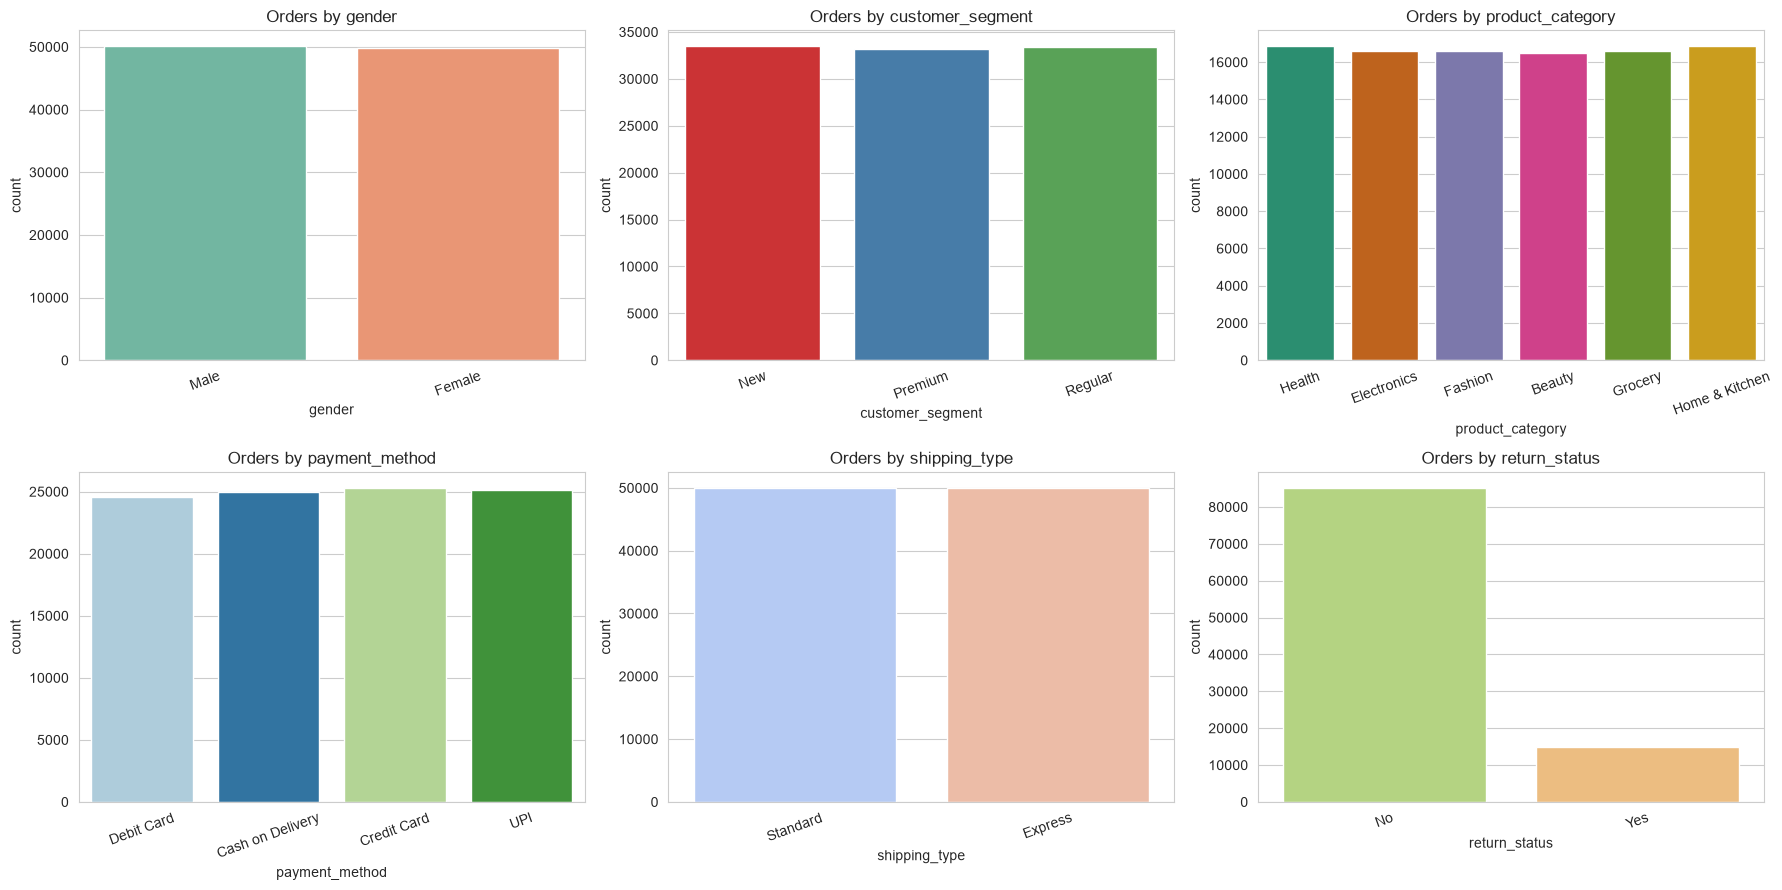

In [17]:
plot_cols = ["gender", "customer_segment", "product_category", "payment_method", "shipping_type", "return_status"]
palettes = ["Set2", "Set1", "Dark2", "Paired", "coolwarm", "RdYlGn_r"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col, palette in zip(axes.flatten(), plot_cols, palettes):
    sns.countplot(data=retail_data, x=col, hue=col, palette=palette, legend=False, ax=ax)
    ax.set_title("Orders by " + col)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("outputs/figures/03_countplots.png", bbox_inches="tight")
plt.show()

### 5.3 City and state

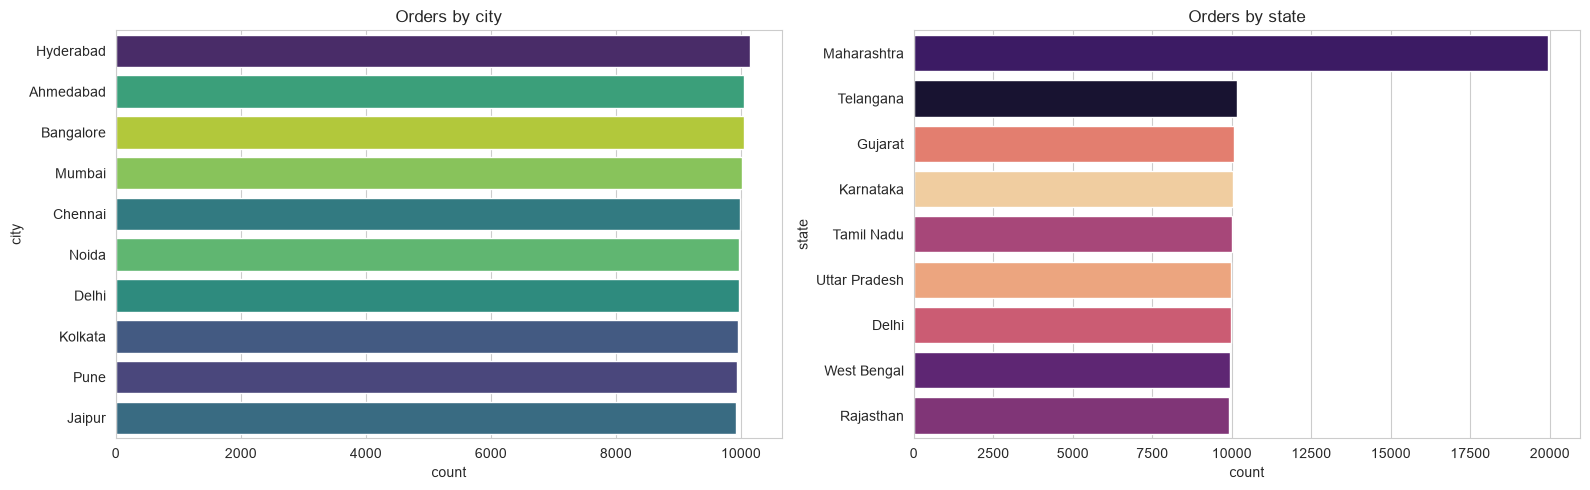

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

city_order = retail_data["city"].value_counts().index
sns.countplot(data=retail_data, y="city", hue="city", order=city_order, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Orders by city")

state_order = retail_data["state"].value_counts().index
sns.countplot(data=retail_data, y="state", hue="state", order=state_order, palette="magma", legend=False, ax=axes[1])
axes[1].set_title("Orders by state")

plt.tight_layout()
plt.savefig("outputs/figures/04_city_state.png", bbox_inches="tight")
plt.show()

### 5.4 Subcategories and customer segments (using hue)

In the left chart the colour shows which category the subcategory belongs to. In the right chart the colour shows the customer segment.

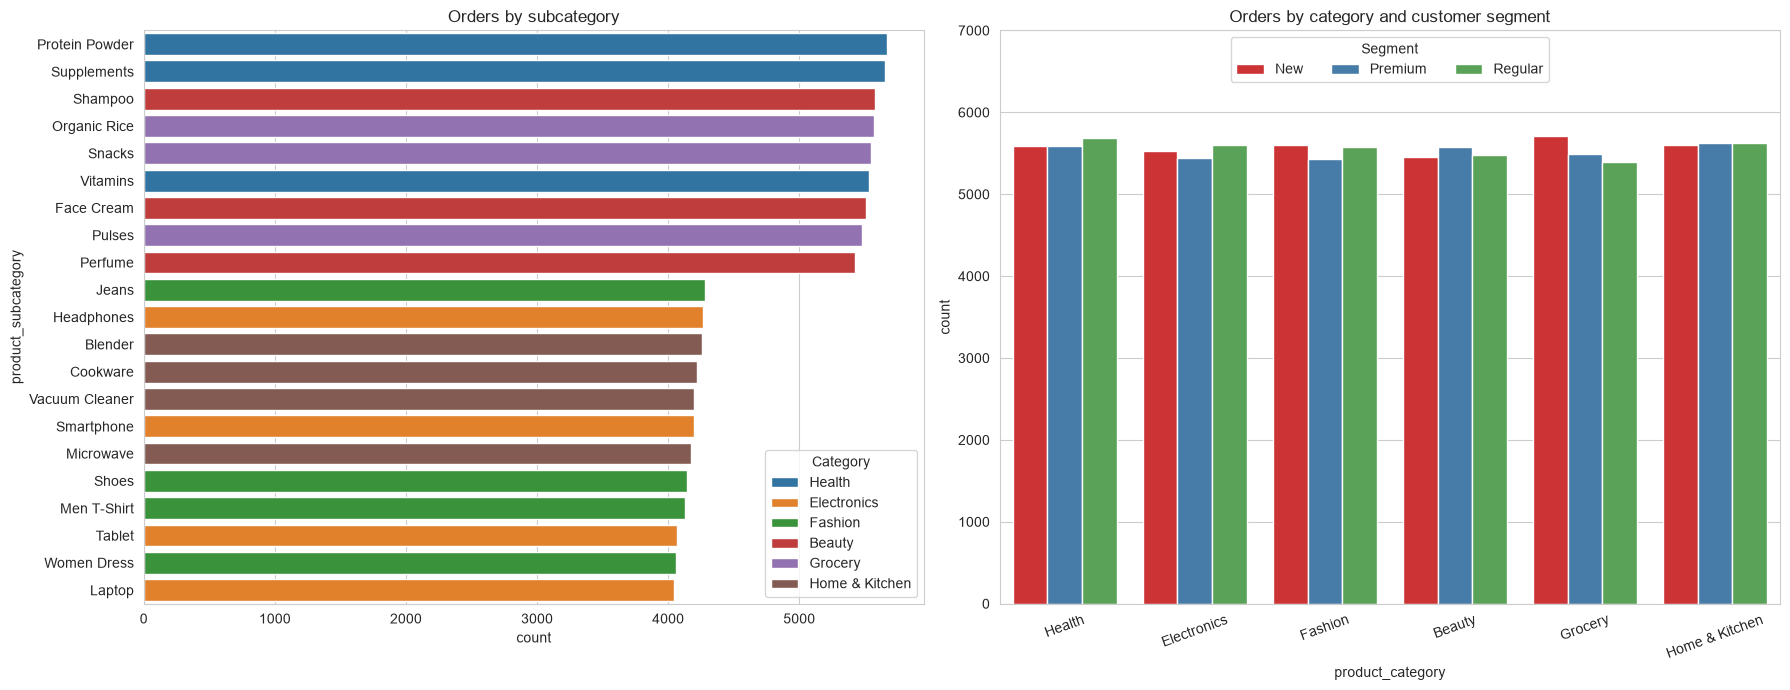

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sub_order = retail_data["product_subcategory"].value_counts().index
sns.countplot(data=retail_data, y="product_subcategory", hue="product_category", order=sub_order,
              dodge=False, palette="tab10", ax=axes[0])
axes[0].set_title("Orders by subcategory")
axes[0].legend(title="Category", loc="lower right")

sns.countplot(data=retail_data, x="product_category", hue="customer_segment", palette="Set1", ax=axes[1])
axes[1].set_title("Orders by category and customer segment")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylim(0, 7000)
axes[1].legend(title="Segment", ncol=3, loc="upper center")

plt.tight_layout()
plt.savefig("outputs/figures/05_subcategory_segment.png", bbox_inches="tight")
plt.show()

### 5.5 Pie (donut) charts

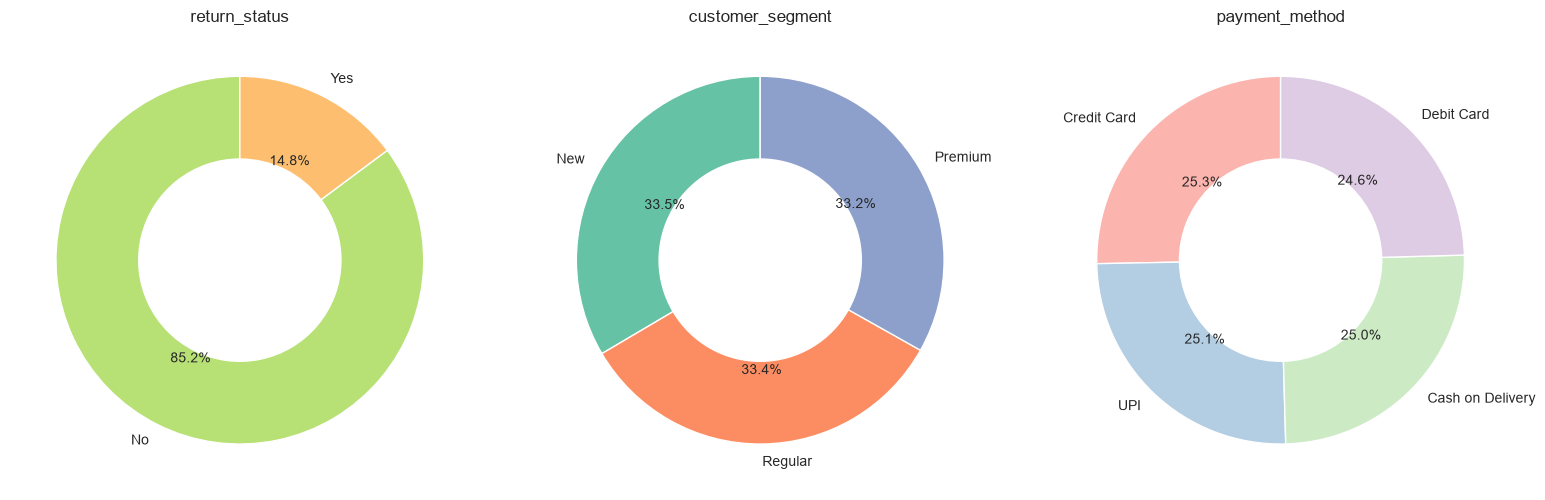

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, palette in zip(axes, ["return_status", "customer_segment", "payment_method"], ["RdYlGn_r", "Set2", "Pastel1"]):
    counts = retail_data[col].value_counts()
    ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette(palette, len(counts)), wedgeprops=dict(width=0.45, edgecolor="white"))
    ax.set_title(col)

plt.tight_layout()
plt.savefig("outputs/figures/06_donut_charts.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* The data is very balanced. Male and female are 50.1% and 49.9%. The segments are New 33.5%, Regular 33.4% and Premium 33.2%. Payment methods are between 24.6% and 25.3% and Express and Standard are 50% each. Every city has about 10% of the orders. So there is no majority segment and Regular is not the biggest.
* The product categories are between 16.5% and 16.9%. Health is the highest and Beauty the lowest, but the gap is tiny. Electronics (16.6%) is not the top category.
* Maharashtra has about 20% of the orders, double of the other states, only because it has two cities (Mumbai and Pune).
* In the subcategory chart, the subcategories of Health, Grocery and Beauty have about 5,500 orders each and the others about 4,200. The reason is that these three categories have 3 subcategories each while Electronics, Fashion and Home & Kitchen have 4. The categories are equal in size, so the orders are just divided between more products. It does not mean some products sell better.
* The return status is the only column which is not balanced. 14.81% of the orders (14,811) were returned.
* In the right chart of 5.4 the three segments have almost the same height in every category.

## 6. Outlier Detection and Capping

**Objective:** Find extreme values using two methods (IQR method and Z-score method), understand what these orders are, and then cap them. The original `final_price` is kept as it is and the capped values go into a new column, so nothing is lost.

* IQR method: a value is an outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.
* Z-score method: a value is an outlier if it is more than 3 standard deviations away from the mean.

### 6.1 Outliers in each numerical column

In [21]:
rows = []
for col in num_cols:
    q1 = retail_data[col].quantile(0.25)
    q3 = retail_data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_outliers = ((retail_data[col] < lower) | (retail_data[col] > upper)).sum()

    z_score = (retail_data[col] - retail_data[col].mean()) / retail_data[col].std()
    z_outliers = (z_score.abs() > 3).sum()

    rows.append([col, lower, upper, iqr_outliers, z_outliers])

outlier_table = pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "IQR_outliers", "Zscore_outliers"])
outlier_table.set_index("column")

,lower_limit,upper_limit,IQR_outliers,Zscore_outliers
column,,,,
age,-6.00,90.00,0,0
product_price,"-28,998.00","89,330.00",0,0
quantity,-3.50,8.50,0,0
discount_percentage,-17.00,47.00,0,0
final_price,"-79,306.60","198,057.67",1335,503
delivery_days,-4.50,15.50,0,0


### 6.2 Which orders are the outliers?

Only `final_price` has outliers, so let us see what kind of orders they are before deciding anything.

Upper limit for final_price: 198057.68
Number of outlier orders: 1335 out of 100000

Average of normal orders and outlier orders:


,quantity,product_price,discount_percentage,final_price
is_outlier,,,,
False,2.48,"29,811.58",15.14,"62,164.67"
True,4.00,"56,249.43",5.65,"212,056.44"


Quantity of the outlier orders:
quantity
4    1335
Name: count, dtype: int64


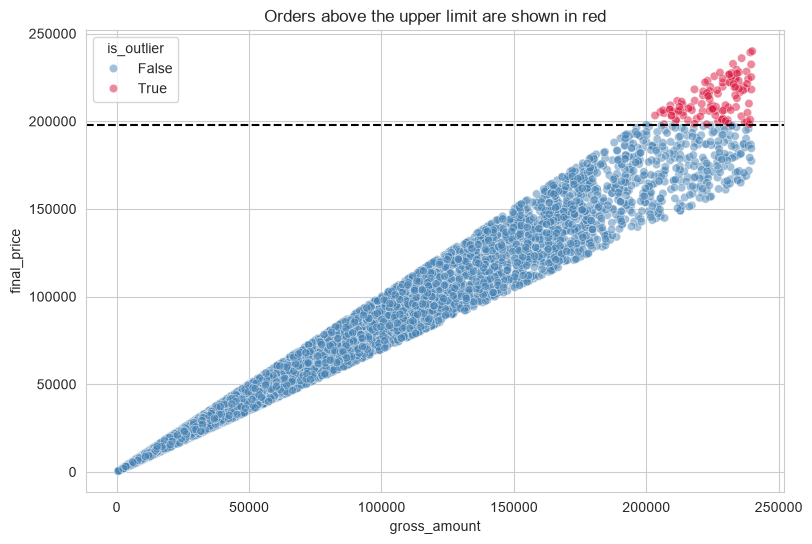

In [22]:
q1 = retail_data["final_price"].quantile(0.25)
q3 = retail_data["final_price"].quantile(0.75)
lower_limit = q1 - 1.5 * (q3 - q1)
upper_limit = q3 + 1.5 * (q3 - q1)

retail_data["is_outlier"] = (retail_data["final_price"] > upper_limit) | (retail_data["final_price"] < lower_limit)
print("Upper limit for final_price:", round(upper_limit, 2))
print("Number of outlier orders:", retail_data["is_outlier"].sum(), "out of", len(retail_data))
print()

print("Average of normal orders and outlier orders:")
display(retail_data.groupby("is_outlier")[["quantity", "product_price", "discount_percentage", "final_price"]].mean())

print("Quantity of the outlier orders:")
print(retail_data[retail_data["is_outlier"]]["quantity"].value_counts())

# chart: gross amount vs final price, outliers in red
sample = retail_data.sample(8000, random_state=1)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="gross_amount", y="final_price", hue="is_outlier",
                palette={False: "steelblue", True: "crimson"}, alpha=0.5)
plt.axhline(upper_limit, color="black", linestyle="--")
plt.title("Orders above the upper limit are shown in red")
plt.savefig("outputs/figures/07_outliers.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* Only `final_price` has outliers. The IQR method gives 1,335 orders (1.3%) above the upper limit of 198,058, and the Z-score method gives 503 (0.5%). Z-score gives fewer, probably because it works best for bell-shaped data and this column is skewed. The other five columns have no outliers.
* All 1,335 outlier orders have quantity 4, a high unit price (average 56,249 against 29,812 for normal orders) and a low discount (5.7% against 15.1%). So they are just the biggest possible orders, not mistakes. In the scatter plot the red dots are at the top right.
* Because they are real orders, I kept them in the analysis and capped them only in a separate column.

### 6.3 Capping the outliers

Every value above the upper limit is replaced by the upper limit itself. The result is saved in the new column `final_price_capped`.

,before capping,after capping
count,"100,000.00","100,000.00"
mean,"64,165.72","63,978.84"
std,"49,969.28","49,425.72"
min,357.00,357.00
25%,"24,705.00","24,705.00"
50%,"49,752.39","49,752.39"
75%,"94,046.07","94,046.07"
max,"239,980.00","198,057.67"
skewness,0.93,0.88


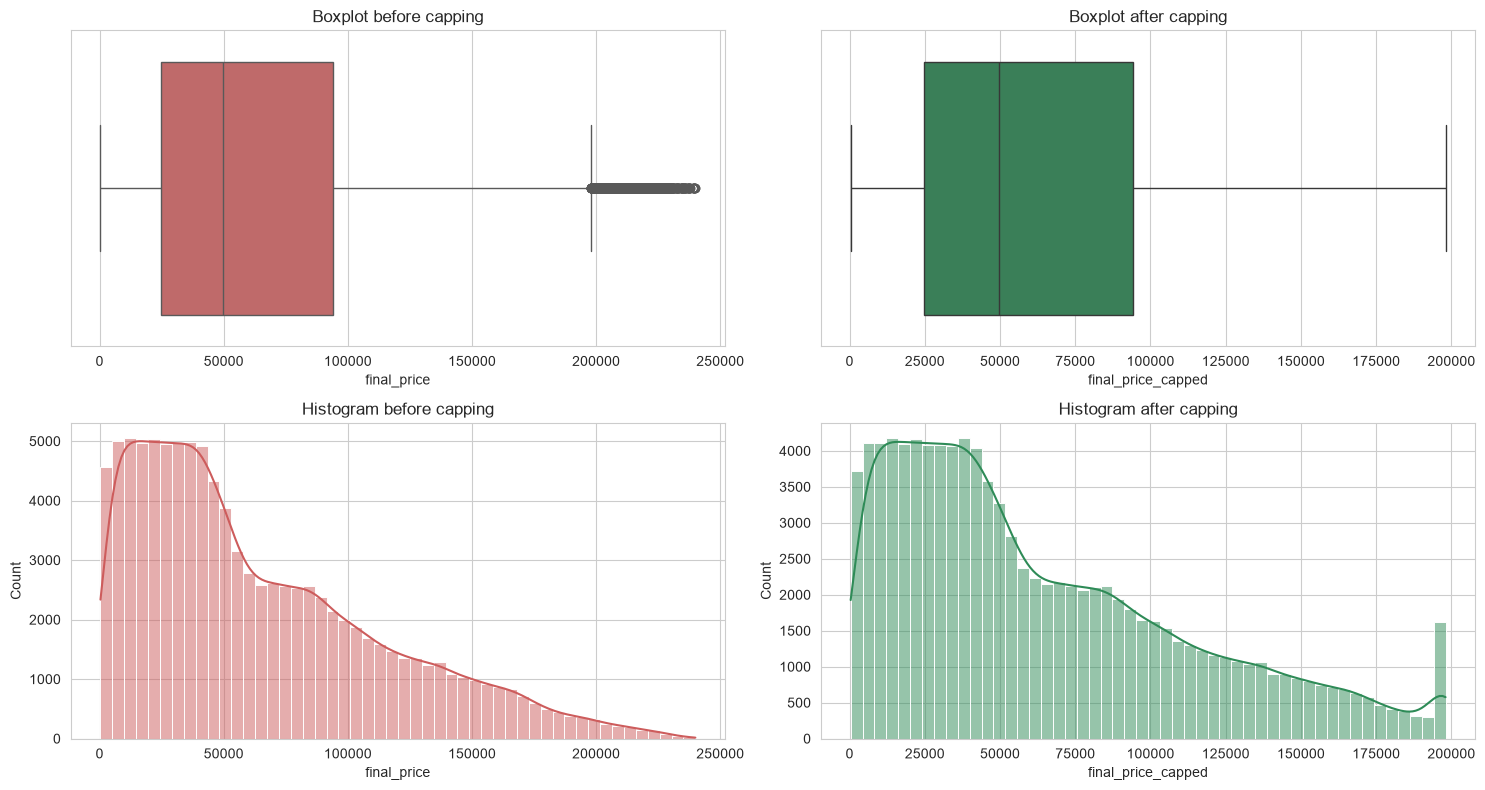

In [23]:
retail_data["final_price_capped"] = retail_data["final_price"].clip(lower=lower_limit, upper=upper_limit)

compare = pd.DataFrame({"before capping": retail_data["final_price"].describe(),
                        "after capping": retail_data["final_price_capped"].describe()})
compare.loc["skewness"] = [retail_data["final_price"].skew(), retail_data["final_price_capped"].skew()]
display(compare)

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
sns.boxplot(x=retail_data["final_price"], color="indianred", ax=axes[0, 0])
axes[0, 0].set_title("Boxplot before capping")
sns.boxplot(x=retail_data["final_price_capped"], color="seagreen", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot after capping")
sns.histplot(retail_data["final_price"], bins=50, kde=True, color="indianred", ax=axes[1, 0])
axes[1, 0].set_title("Histogram before capping")
sns.histplot(retail_data["final_price_capped"], bins=50, kde=True, color="seagreen", ax=axes[1, 1])
axes[1, 1].set_title("Histogram after capping")

plt.tight_layout()
plt.savefig("outputs/figures/08_capping.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* Capping replaced the 1,335 values with 198,058. The mean went from 64,166 to 63,979 (about 0.3% less), the median did not change (49,752), the maximum came down from 239,980 to 198,058 and the skewness went from 0.93 to 0.88.
* After capping the boxplot has no dots. The histogram has a small bump at the end because all the capped values are now at the same point.
* Only 1.3% of the rows were changed, so the effect of capping is small.

### 6.4 Do the results change after capping? Save the cleaned data

To be sure that capping does not change the story, the average order value of each customer segment and the correlations are compared for both columns. After that the cleaned data is saved as `Processed_dataset.csv`.

In [24]:
print("Average order value by customer segment")
display(retail_data.groupby("customer_segment")[["final_price", "final_price_capped"]].mean())

print("Correlation with final_price and with final_price_capped")
display(pd.DataFrame({
    "with final_price": retail_data[["product_price", "quantity", "discount_percentage", "age", "delivery_days"]].corrwith(retail_data["final_price"]),
    "with final_price_capped": retail_data[["product_price", "quantity", "discount_percentage", "age", "delivery_days"]].corrwith(retail_data["final_price_capped"]),
}))

retail_data.to_csv("data/Processed_dataset.csv", index=False)
print("Saved data/Processed_dataset.csv with", retail_data.shape[0], "rows and", retail_data.shape[1], "columns")

Average order value by customer segment


,final_price,final_price_capped
customer_segment,,
New,"63,766.75","63,584.86"
Premium,"64,430.45","64,243.79"
Regular,"64,303.15","64,111.04"


Correlation with final_price and with final_price_capped


,with final_price,with final_price_capped
product_price,0.73,0.73
quantity,0.58,0.58
discount_percentage,-0.14,-0.13
age,-0.00,-0.00
delivery_days,0.00,0.00


Saved data/Processed_dataset.csv with 100000 rows and 30 columns


**Interpretation:**

* After capping the average of every segment goes down by about 0.3% and the order is the same (Premium, Regular, New). The correlations are also the same: price 0.73, quantity 0.58, discount -0.14 (-0.13 after capping), and age and delivery days 0.00.
* So capping does not change the results. This is one more reason to treat the outliers as valid orders.
* `Processed_dataset.csv` is saved with 100,000 rows and 30 columns (the 18 original ones, the new columns, the outlier flag and the capped price).

## 7. Bivariate Analysis: Numerical vs Numerical

**Objective:** Check how two numerical columns move together using scatter plots and Pearson correlation. A correlation near +1 means they increase together, near -1 means one goes down when the other goes up, and near 0 means no linear relation.

### 7.1 Scatter plots

Scatter plots use a random sample of 6,000 orders, otherwise 100,000 dots would hide each other.

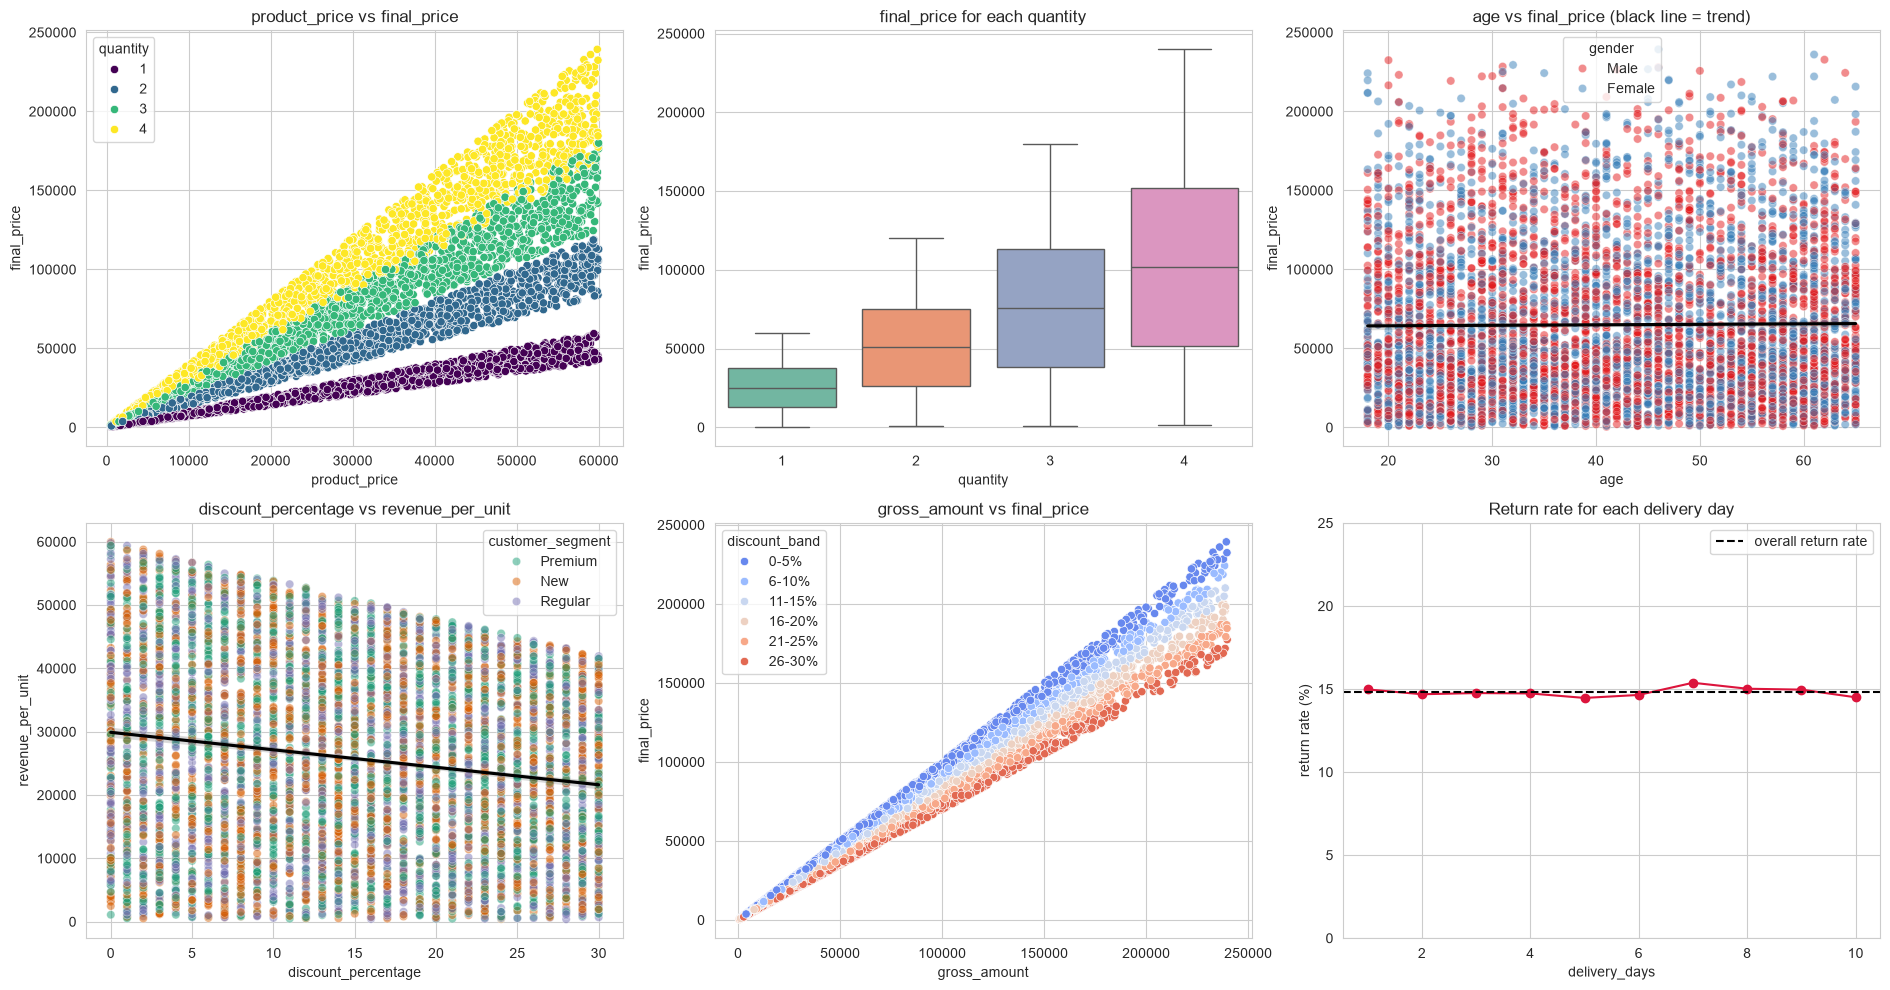

In [25]:
sample = retail_data.sample(6000, random_state=1)

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

sns.scatterplot(data=sample, x="product_price", y="final_price", hue="quantity", palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("product_price vs final_price")

sns.boxplot(data=retail_data, x="quantity", y="final_price", hue="quantity", palette="Set2", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("final_price for each quantity")

sns.scatterplot(data=sample, x="age", y="final_price", hue="gender", palette="Set1", alpha=0.5, ax=axes[0, 2])
sns.regplot(data=sample, x="age", y="final_price", scatter=False, color="black", ax=axes[0, 2])
axes[0, 2].set_title("age vs final_price (black line = trend)")

sns.scatterplot(data=sample, x="discount_percentage", y="revenue_per_unit", hue="customer_segment",
                palette="Dark2", alpha=0.5, ax=axes[1, 0])
sns.regplot(data=sample, x="discount_percentage", y="revenue_per_unit", scatter=False, color="black", ax=axes[1, 0])
axes[1, 0].set_title("discount_percentage vs revenue_per_unit")

sns.scatterplot(data=sample, x="gross_amount", y="final_price", hue="discount_band", palette="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("gross_amount vs final_price")

# return rate for each delivery day
return_by_days = retail_data.groupby("delivery_days")["is_return"].mean() * 100
axes[1, 2].plot(return_by_days.index, return_by_days.values, marker="o", color="crimson")
axes[1, 2].axhline(retail_data["is_return"].mean() * 100, color="black", linestyle="--", label="overall return rate")
axes[1, 2].set_ylim(0, 25)
axes[1, 2].set_xlabel("delivery_days")
axes[1, 2].set_ylabel("return rate (%)")
axes[1, 2].set_title("Return rate for each delivery day")
axes[1, 2].legend()

plt.tight_layout()
plt.savefig("outputs/figures/09_scatter_plots.png", bbox_inches="tight")
plt.show()

### 7.2 Correlation heatmap

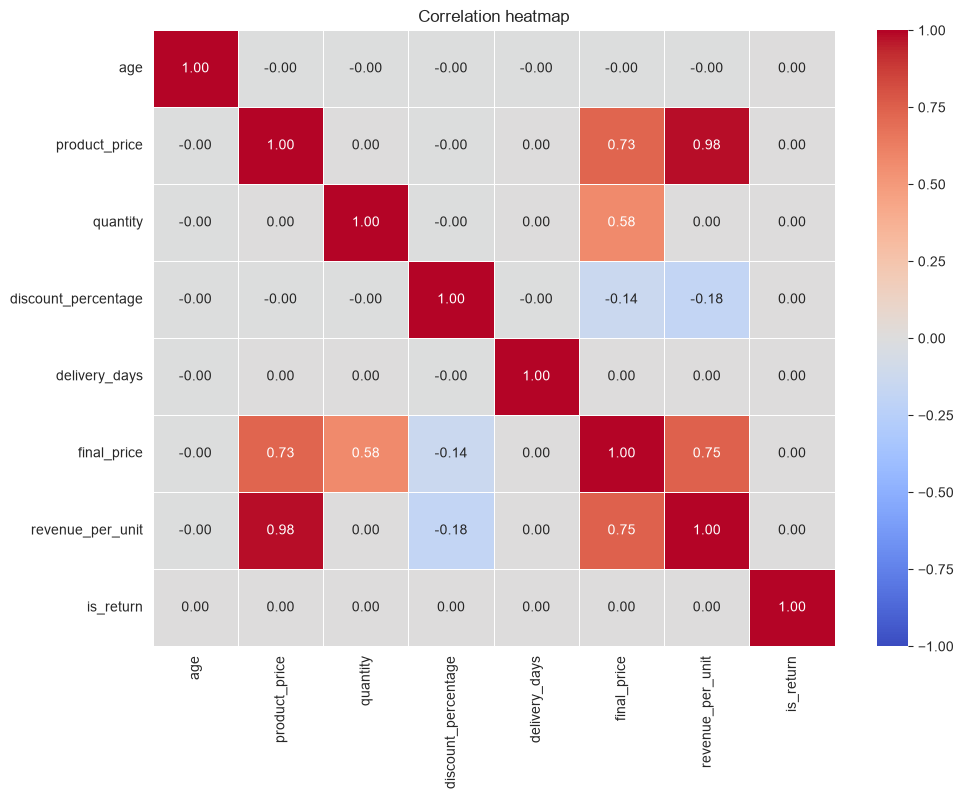

Correlation of final_price with the other columns:


,correlation
revenue_per_unit,0.75
product_price,0.73
quantity,0.58
delivery_days,0.00
is_return,0.00
age,-0.00
discount_percentage,-0.14


In [26]:
corr_cols = ["age", "product_price", "quantity", "discount_percentage", "delivery_days",
             "final_price", "revenue_per_unit", "is_return"]
correlation = retail_data[corr_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation heatmap")
plt.savefig("outputs/figures/10_correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("Correlation of final_price with the other columns:")
correlation["final_price"].drop("final_price").sort_values(ascending=False).to_frame("correlation")

**Interpretation:**

* `final_price` has a correlation of 0.73 with product_price, 0.58 with quantity and -0.14 with discount_percentage. In the scatter plot `final_price` divides into four bands, one for each quantity, and the median order value goes from about 25,000 (1 unit) to about 100,000 (4 units). A higher discount pulls the final price down.
* But as we saw in 3.4, `final_price` is calculated from these three columns, so these relations only confirm the formula. They do not tell us anything about customer behaviour.
* Age has no relation with spending (the black line is flat and the correlation is 0.00), so older customers do not spend more. Delivery days also has 0.00.
* `is_return` has a correlation of 0.00 with every column. The return rate for each delivery day stays near 14.8%, so a longer delivery does not mean more returns.
* The input columns (age, price, quantity, discount, delivery days) have about 0 correlation with each other. `revenue_per_unit` and `product_price` are highly correlated (0.98) only because one is made from the other.

## 8. Bivariate Analysis: Numerical vs Categorical

**Objective:** Compare spending (`final_price`) and delivery time between groups like customer segment, category, payment method, shipping type, gender, age group and city.

### 8.1 Average and median order value of each group

The median is also shown, because `final_price` has a long tail on the right and the mean gets pulled up by big orders.

In [27]:
for col in ["customer_segment", "product_category", "payment_method", "shipping_type", "gender", "age_group", "city"]:
    print("Order value by", col)
    display(retail_data.groupby(col, observed=True)["final_price"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False))

Order value by customer_segment


,mean,median,count
customer_segment,,,
Premium,"64,430.45","50,273.88",33151
Regular,"64,303.15","49,767.84",33361
New,"63,766.75","49,224.52",33488


Order value by product_category


,mean,median,count
product_category,,,
Home & Kitchen,"64,840.42","50,366.47",16848
Electronics,"64,329.67","50,195.79",16576
Grocery,"64,101.81","49,478.34",16592
Beauty,"64,030.55","49,621.32",16513
Fashion,"64,002.19","49,765.24",16613
Health,"63,686.69","49,294.98",16858


Order value by payment_method


,mean,median,count
payment_method,,,
Debit Card,"64,714.76","50,282.84",24560
UPI,"64,104.53","49,640.80",25139
Credit Card,"63,962.02","49,454.61",25307
Cash on Delivery,"63,894.03","49,628.15",24994


... (4 outputs left out)

Order value by age_group


,mean,median,count
age_group,,,
26-35,"64,600.49","49,893.48",20718
46-55,"64,411.14","50,064.14",20908
36-45,"64,004.92","49,647.76",20815
18-25,"63,903.33","49,132.48",16599
56-65,"63,858.66","49,990.13",20960


Order value by city


,mean,median,count
city,,,
Chennai,"65,107.98","50,638.80",9993
Mumbai,"64,787.77","50,402.88",10015
Jaipur,"64,481.22","49,277.34",9920
Kolkata,"64,286.89","49,872.00",9955
Ahmedabad,"64,102.31","49,816.20",10057
Hyderabad,"64,081.53","49,658.28",10150
Pune,"63,824.77","49,323.00",9937
Noida,"63,818.44","49,446.29",9964
Bangalore,"63,795.19","49,212.90",10047


### 8.2 Average order value (bar charts)

The dashed line is the overall average. The bars start from zero so the differences are not exaggerated.

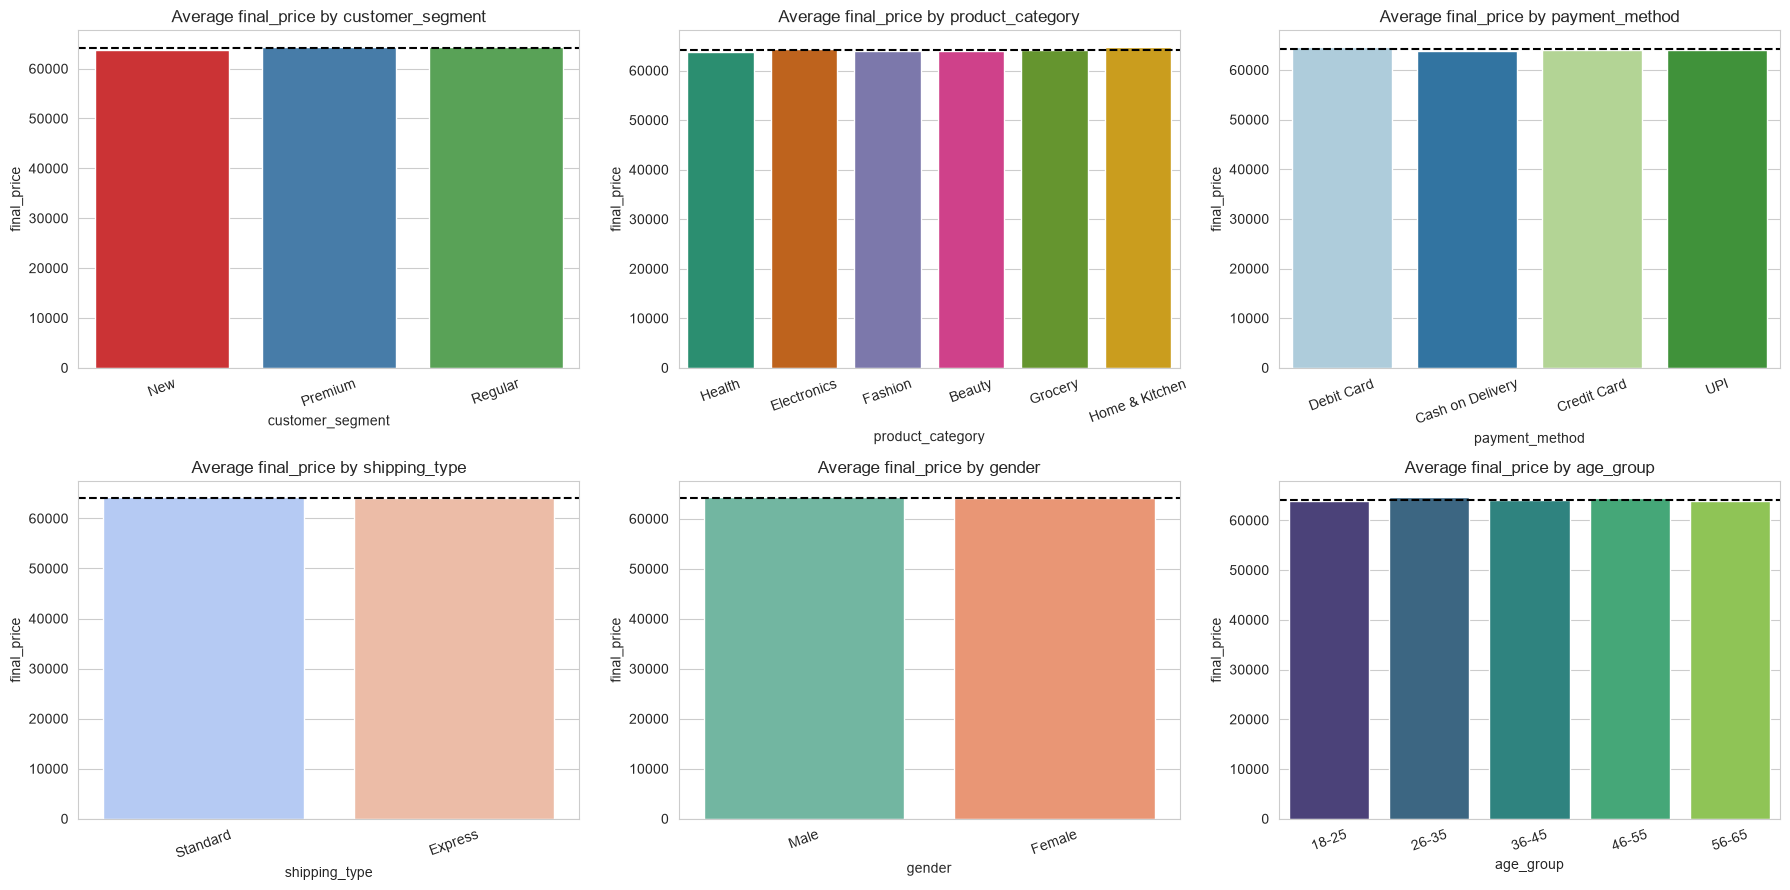

In [28]:
group_cols = ["customer_segment", "product_category", "payment_method", "shipping_type", "gender", "age_group"]
palettes = ["Set1", "Dark2", "Paired", "coolwarm", "Set2", "viridis"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col, palette in zip(axes.flatten(), group_cols, palettes):
    sns.barplot(data=retail_data, x=col, y="final_price", hue=col, palette=palette,
                errorbar=None, dodge=False, legend=False, ax=ax)
    ax.axhline(retail_data["final_price"].mean(), color="black", linestyle="--")
    ax.set_title("Average final_price by " + col)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("outputs/figures/11_average_by_group.png", bbox_inches="tight")
plt.show()

### 8.3 Boxplots and violin plots

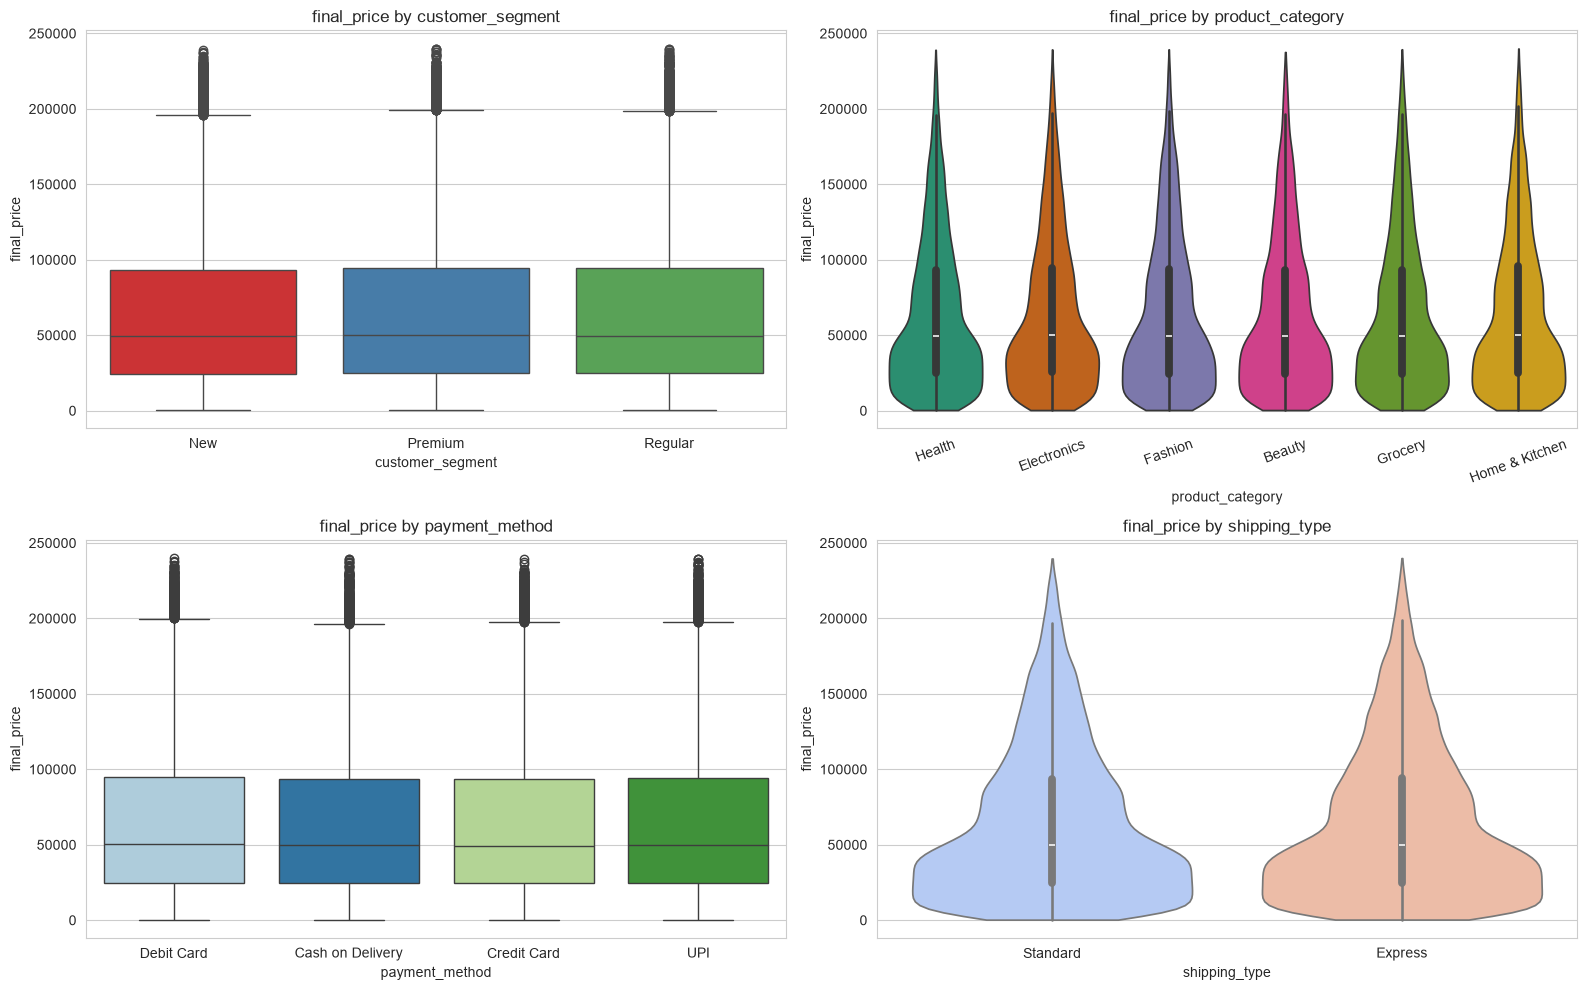

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.boxplot(data=retail_data, x="customer_segment", y="final_price", hue="customer_segment", palette="Set1", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("final_price by customer_segment")

sns.violinplot(data=retail_data, x="product_category", y="final_price", hue="product_category", palette="Dark2",
               legend=False, cut=0, ax=axes[0, 1])
axes[0, 1].set_title("final_price by product_category")
axes[0, 1].tick_params(axis="x", rotation=20)

sns.boxplot(data=retail_data, x="payment_method", y="final_price", hue="payment_method", palette="Paired", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("final_price by payment_method")

sns.violinplot(data=retail_data, x="shipping_type", y="final_price", hue="shipping_type", palette="coolwarm",
               legend=False, cut=0, ax=axes[1, 1])
axes[1, 1].set_title("final_price by shipping_type")

plt.tight_layout()
plt.savefig("outputs/figures/12_boxplots_violins.png", bbox_inches="tight")
plt.show()

### 8.4 Shipping type and delivery days

The expectation is that Express shipping should deliver faster than Standard, so this is checked here.

               mean  median  min  max
shipping_type                        
Express        5.50    5.00    1   10
Standard       5.51    6.00    1   10


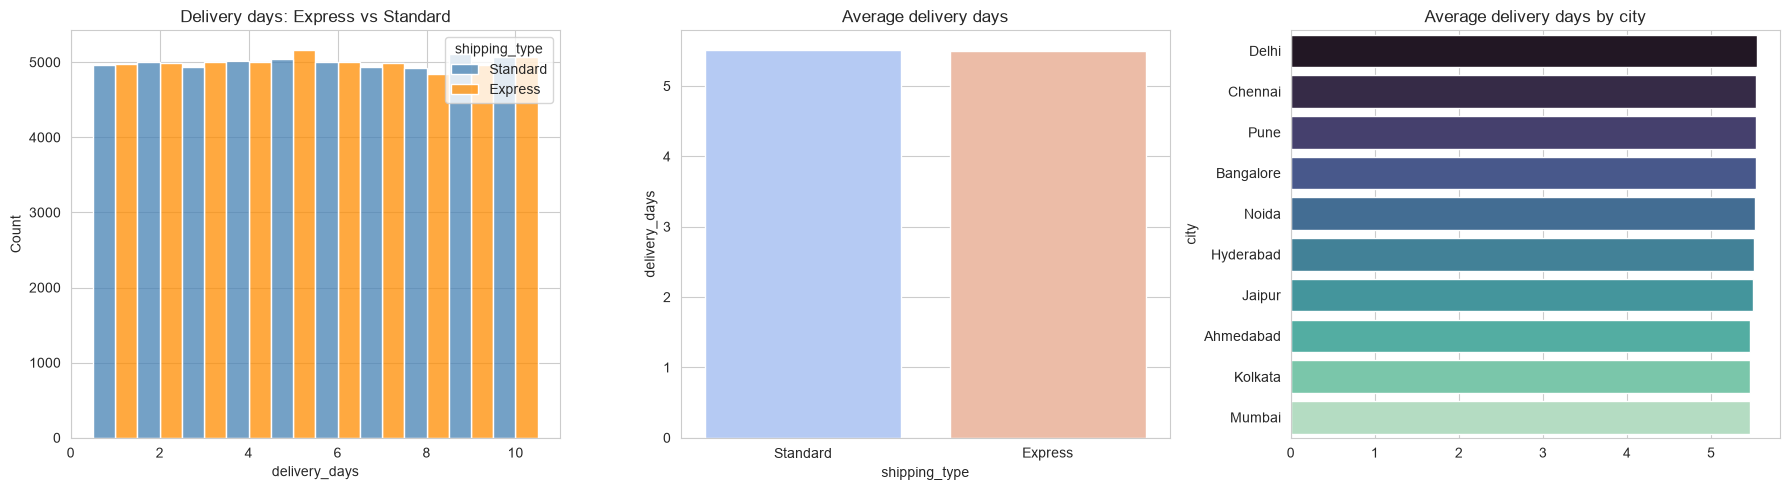

In [30]:
print(retail_data.groupby("shipping_type")["delivery_days"].agg(["mean", "median", "min", "max"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=retail_data, x="delivery_days", hue="shipping_type", multiple="dodge", discrete=True,
             palette=["steelblue", "darkorange"], ax=axes[0])
axes[0].set_title("Delivery days: Express vs Standard")

sns.barplot(data=retail_data, x="shipping_type", y="delivery_days", hue="shipping_type", palette="coolwarm",
            errorbar=None, legend=False, ax=axes[1])
axes[1].set_title("Average delivery days")

city_days = retail_data.groupby("city")["delivery_days"].mean().sort_values(ascending=False)
sns.barplot(x=city_days.values, y=city_days.index, hue=city_days.index, palette="mako", legend=False, ax=axes[2])
axes[2].set_title("Average delivery days by city")

plt.tight_layout()
plt.savefig("outputs/figures/13_delivery_days.png", bbox_inches="tight")
plt.show()

### 8.5 Is the difference real or just chance?

The averages of the groups are a little different, but with so many orders it is hard to say by just looking. So a statistical test is used. ANOVA is used when comparing more than two groups and the t-test when there are two groups. If the **p-value is more than 0.05**, the difference can easily be just chance.

In [31]:
rows = []
for col in ["customer_segment", "product_category", "payment_method", "gender", "age_group", "city"]:
    groups = [g["final_price"] for _, g in retail_data.groupby(col, observed=True)]
    f_value, p_value = stats.f_oneway(*groups)
    rows.append(["final_price", col, "ANOVA", round(p_value, 3)])

# Express vs Standard delivery days
express = retail_data[retail_data["shipping_type"] == "Express"]["delivery_days"]
standard = retail_data[retail_data["shipping_type"] == "Standard"]["delivery_days"]
t_value, p_value = stats.ttest_ind(express, standard)
rows.append(["delivery_days", "shipping_type", "t-test", round(p_value, 3)])

test_table = pd.DataFrame(rows, columns=["compared column", "grouped by", "test", "p-value"])
test_table["real difference?"] = np.where(test_table["p-value"] < 0.05, "Yes", "No")
test_table

,compared column,grouped by,test,p-value,real difference?
0,final_price,customer_segment,ANOVA,0.19,No
1,final_price,product_category,ANOVA,0.40,No
2,final_price,payment_method,ANOVA,0.24,No
3,final_price,gender,ANOVA,0.56,No
4,final_price,age_group,ANOVA,0.47,No
5,final_price,city,ANOVA,0.38,No
6,delivery_days,shipping_type,t-test,0.37,No


**Interpretation:**

* The average order value of the groups is very close. By segment: New 63,767, Regular 64,303, Premium 64,430. Premium is the highest but only about 1% above New. By category it goes from 63,687 (Health) to 64,840 (Home & Kitchen), by payment method from 63,894 to 64,715 (Debit Card), by age group from 63,859 to 64,600 (26-35), and by city from 63,371 (Delhi) to 65,108 (Chennai). Male and female are 64,257 and 64,074, and Express and Standard are 64,140 and 64,191.
* The medians are also close (about 49,000 to 50,600). In every group the mean is higher than the median, because of the long tail on the right.
* In the bar charts all the bars reach the dashed line, and the boxplots and violins look the same for every group.
* Express and Standard shipping have an average delivery time of 5.50 and 5.51 days, and the two histograms look almost the same. So in this data Express is not faster. Delivery time is also about the same in every city (between 5.46 and 5.54 days).
* In the tests every p-value is above 0.05 (between 0.19 and 0.56, and 0.37 for Express vs Standard). So these differences can easily be just chance.
* So the customer type (segment, gender, age, city) or the payment method does not change the order value. Price, quantity and discount do.

## 9. Bivariate Analysis: Categorical vs Categorical

**Objective:** See if the return rate changes with category, payment method, shipping type, customer segment, gender or delivery speed, and whether the categorical columns are related to each other.

### 9.1 Return rate by group

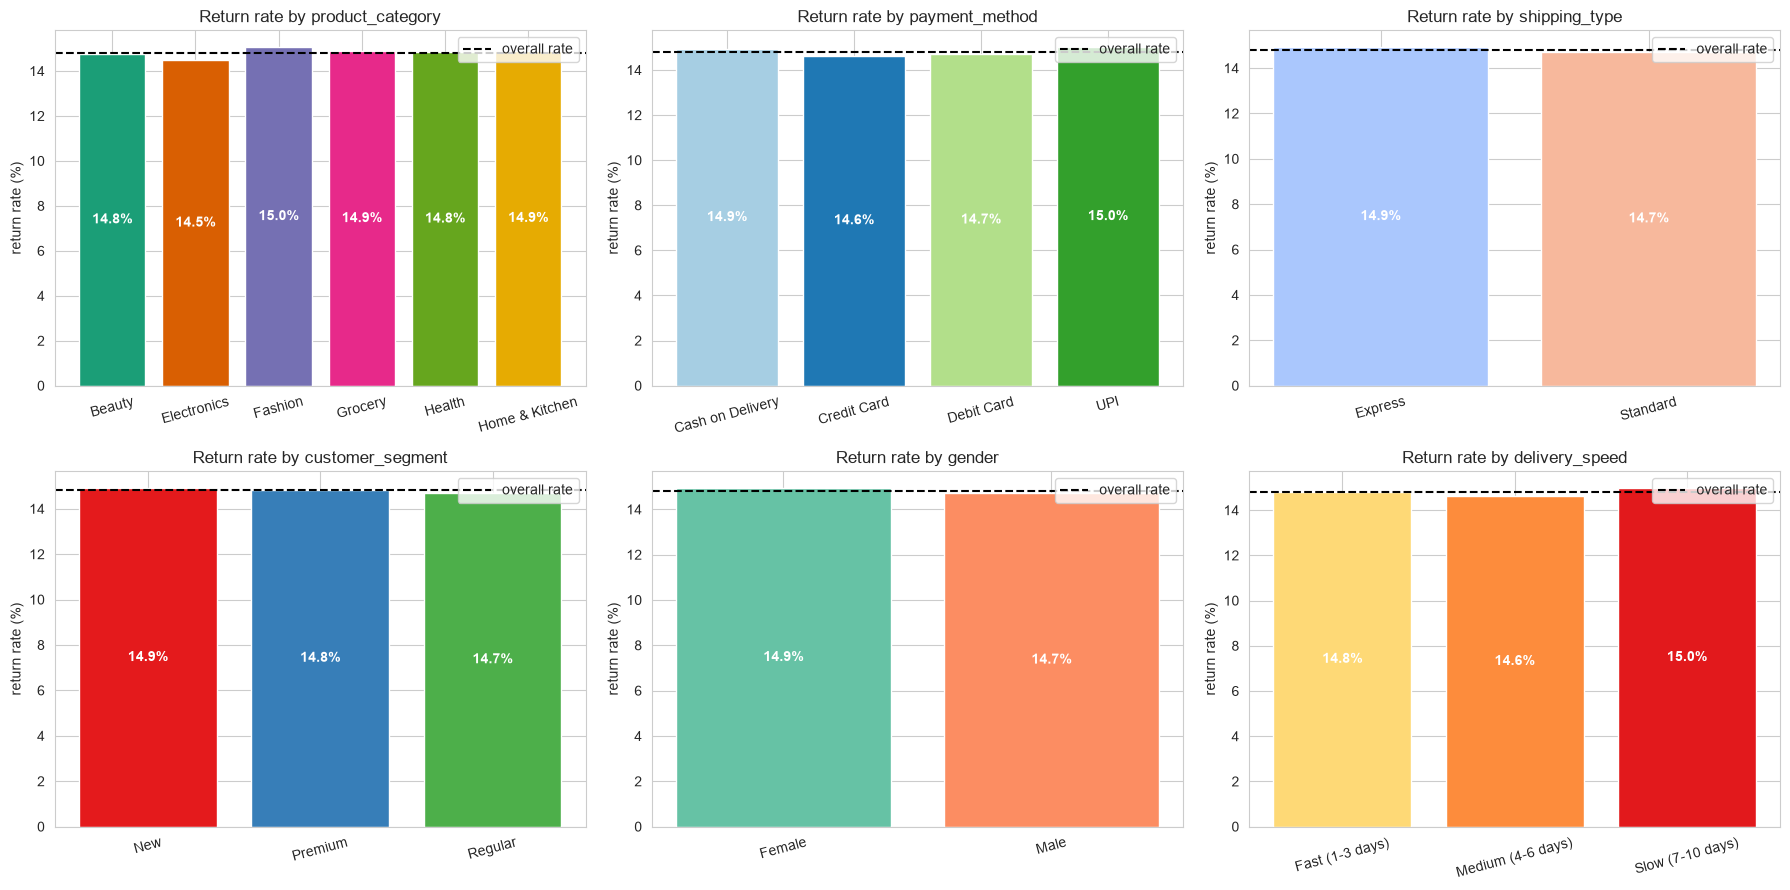

In [32]:
cols = ["product_category", "payment_method", "shipping_type", "customer_segment", "gender", "delivery_speed"]
palettes = ["Dark2", "Paired", "coolwarm", "Set1", "Set2", "YlOrRd"]
overall_rate = retail_data["is_return"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col, palette in zip(axes.flatten(), cols, palettes):
    rate = retail_data.groupby(col, observed=True)["is_return"].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color=sns.color_palette(palette, len(rate)))
    ax.bar_label(bars, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
    ax.axhline(overall_rate, color="black", linestyle="--", label="overall rate")
    ax.set_title("Return rate by " + col)
    ax.set_ylabel("return rate (%)")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig("outputs/figures/14_return_rate_by_group.png", bbox_inches="tight")
plt.show()

### 9.2 Heatmaps of return rate

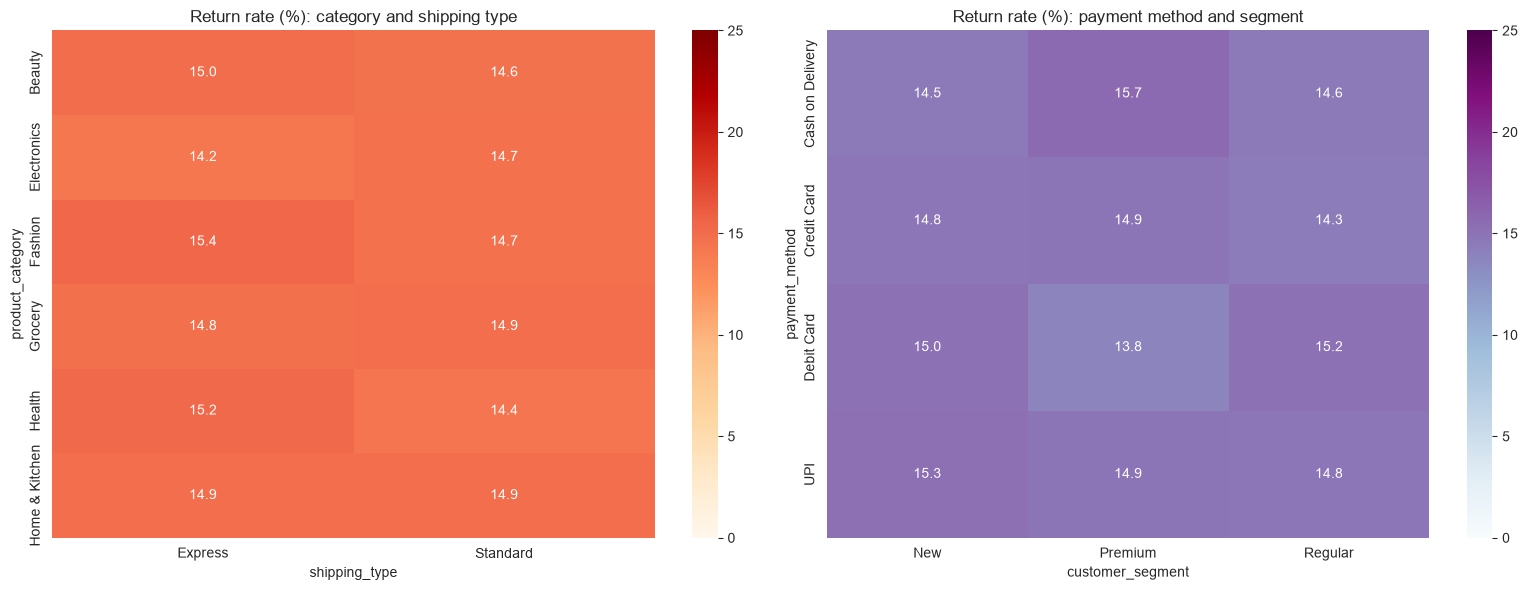

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pivot_1 = retail_data.pivot_table(values="is_return", index="product_category", columns="shipping_type", aggfunc="mean") * 100
sns.heatmap(pivot_1, annot=True, fmt=".1f", cmap="OrRd", vmin=0, vmax=25, ax=axes[0])
axes[0].set_title("Return rate (%): category and shipping type")

pivot_2 = retail_data.pivot_table(values="is_return", index="payment_method", columns="customer_segment", aggfunc="mean") * 100
sns.heatmap(pivot_2, annot=True, fmt=".1f", cmap="BuPu", vmin=0, vmax=25, ax=axes[1])
axes[1].set_title("Return rate (%): payment method and segment")

plt.tight_layout()
plt.savefig("outputs/figures/15_return_rate_heatmaps.png", bbox_inches="tight")
plt.show()

### 9.3 Returned and not returned orders (stacked bars)

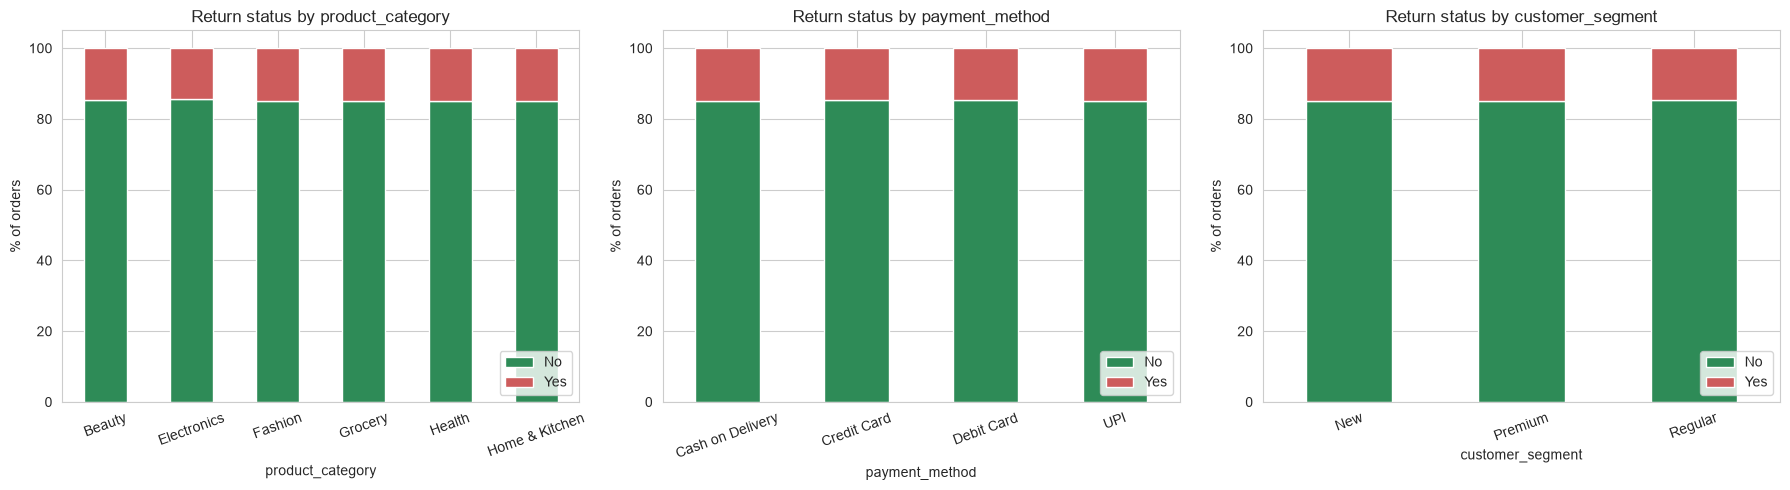

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["product_category", "payment_method", "customer_segment"]):
    share = pd.crosstab(retail_data[col], retail_data["return_status"], normalize="index") * 100
    share.plot(kind="bar", stacked=True, color=["seagreen", "indianred"], ax=ax, rot=20)
    ax.set_title("Return status by " + col)
    ax.set_ylabel("% of orders")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("outputs/figures/16_stacked_bars.png", bbox_inches="tight")
plt.show()

### 9.4 Chi-square test

The chi-square test checks if two categorical columns are related. Again, a **p-value above 0.05** means no clear relation. Here every column is tested against `return_status`.

In [35]:
rows = []
for col in ["product_category", "product_subcategory", "payment_method", "shipping_type", "customer_segment",
            "gender", "city", "age_group", "discount_band", "delivery_speed"]:
    table = pd.crosstab(retail_data[col], retail_data["return_status"])
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    rows.append([col, round(p_value, 3)])

chi_table = pd.DataFrame(rows, columns=["column tested against return_status", "p-value"])
chi_table["related to returns?"] = np.where(chi_table["p-value"] < 0.05, "Yes", "No")
chi_table

,column tested against return_status,p-value,related to returns?
0,product_category,0.79,No
1,product_subcategory,0.24,No
2,payment_method,0.61,No
3,shipping_type,0.38,No
4,customer_segment,0.77,No
5,gender,0.32,No
6,city,0.94,No
7,age_group,0.81,No
8,discount_band,0.47,No
9,delivery_speed,0.43,No


**Interpretation:**

* The overall return rate is 14.81% and all the groups are close to it. By category it is 14.5% (Electronics) to 15.1% (Fashion), by payment method 14.6% to 15.0%, by segment 14.7% to 14.9%, by gender 14.7% and 14.9%, and by delivery speed 14.6% to 15.0%. Electronics has the lowest return rate in the categories, not a higher one, and Standard shipping (14.7%) is not higher than Express (14.9%).
* In the heatmaps every cell is between about 14% and 16% and they all look the same colour on the 0 to 25 scale. The stacked bars show about 85% kept and 15% returned in every group.
* The chi-square test gives a p-value above 0.05 for every column (0.24 to 0.94). So the returns are not related to category, subcategory, payment method, shipping type, segment, gender, city, age group, discount band or delivery speed. The returns look random in this data.
* The subcategories have a bigger gap (13.75% for Cookware to 15.91% for Blender), but each subcategory has only about 4,000 to 5,700 orders, so this is just chance. The test for subcategory also gave p = 0.24.

## 10. Multivariate Analysis

**Objective:** Look at three or more columns at once. We check the three combinations given in the brief (category with discount, segment with age, shipping with delivery days) using pivot tables and heatmaps, and then use a pairplot and a facet grid.

### 10.1 Product category, discount and average final price

discount_band,0-5%,6-10%,11-15%,16-20%,21-25%,26-30%
product_category,,,,,,
Beauty,"72,928.00","70,167.00","65,128.00","61,099.00","57,874.00","55,350.00"
Electronics,"73,734.00","70,157.00","64,795.00","62,932.00","58,105.00","54,095.00"
Fashion,"73,242.00","68,452.00","65,940.00","61,594.00","58,831.00","53,935.00"
Grocery,"74,227.00","70,397.00","64,900.00","63,500.00","57,205.00","52,726.00"
Health,"73,364.00","68,190.00","65,049.00","62,256.00","56,622.00","54,707.00"
Home & Kitchen,"74,502.00","71,391.00","66,690.00","62,319.00","58,328.00","54,036.00"


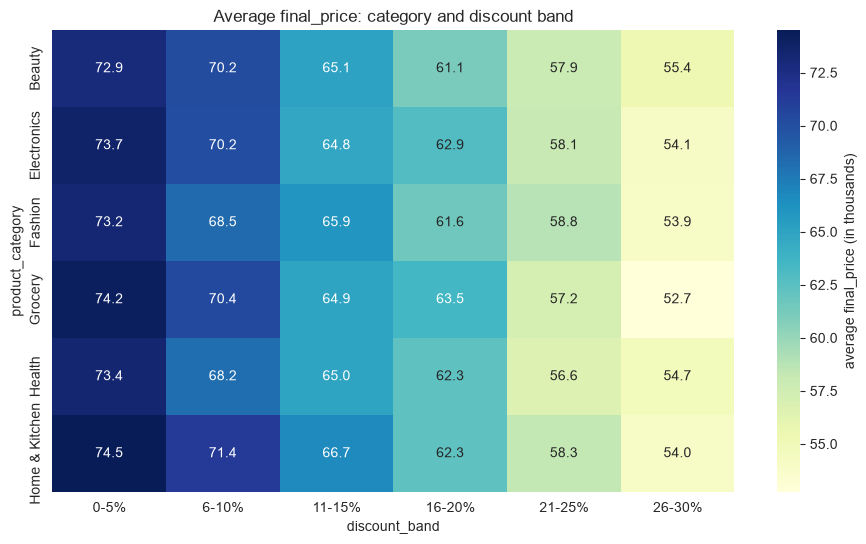

In [36]:
pivot_cd = retail_data.pivot_table(values="final_price", index="product_category", columns="discount_band",
                                   aggfunc="mean", observed=True)
display(pivot_cd.round(0))

plt.figure(figsize=(11, 6))
sns.heatmap(pivot_cd / 1000, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "average final_price (in thousands)"})
plt.title("Average final_price: category and discount band")
plt.savefig("outputs/figures/17_category_discount.png", bbox_inches="tight")
plt.show()

### 10.2 Customer segment, age group and average spending

age_group,18-25,26-35,36-45,46-55,56-65
customer_segment,,,,,
New,"63,588.00","64,165.00","63,879.00","63,513.00","63,659.00"
Premium,"64,026.00","65,282.00","64,034.00","65,432.00","63,295.00"
Regular,"64,097.00","64,359.00","64,104.00","64,295.00","64,616.00"


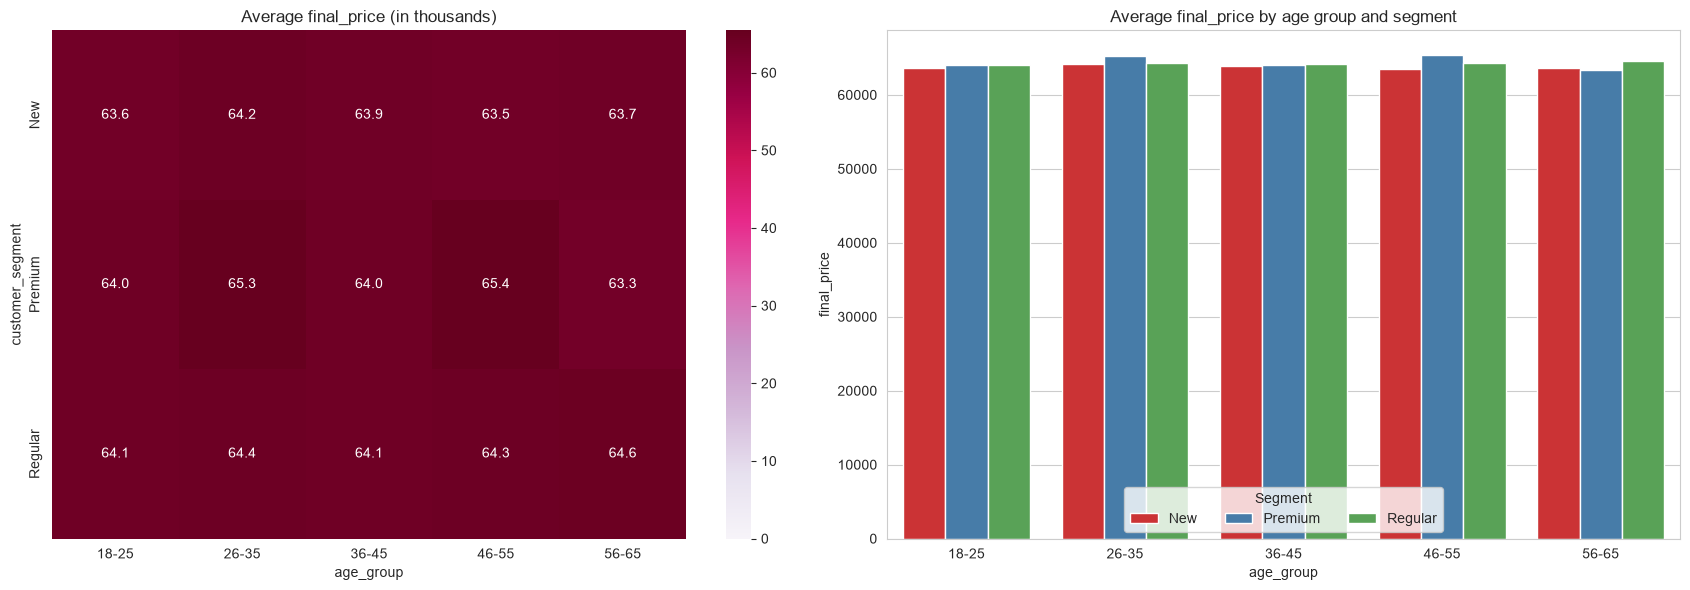

In [37]:
pivot_sa = retail_data.pivot_table(values="final_price", index="customer_segment", columns="age_group",
                                   aggfunc="mean", observed=True)
display(pivot_sa.round(0))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(pivot_sa / 1000, annot=True, fmt=".1f", cmap="PuRd", vmin=0, ax=axes[0])
axes[0].set_title("Average final_price (in thousands)")
sns.barplot(data=retail_data, x="age_group", y="final_price", hue="customer_segment", palette="Set1", errorbar=None, ax=axes[1])
axes[1].set_title("Average final_price by age group and segment")
axes[1].legend(title="Segment", ncol=3, loc="lower center")

plt.tight_layout()
plt.savefig("outputs/figures/18_segment_age.png", bbox_inches="tight")
plt.show()

### 10.3 Shipping type, delivery days and return rate

delivery_days,1,2,3,4,5,6,7,8,9,10
shipping_type,,,,,,,,,,
Express,14.70,14.60,15.20,14.60,15.10,14.40,16.20,14.80,14.80,14.80
Standard,15.20,14.80,14.30,14.90,13.80,14.90,14.50,15.30,15.20,14.20


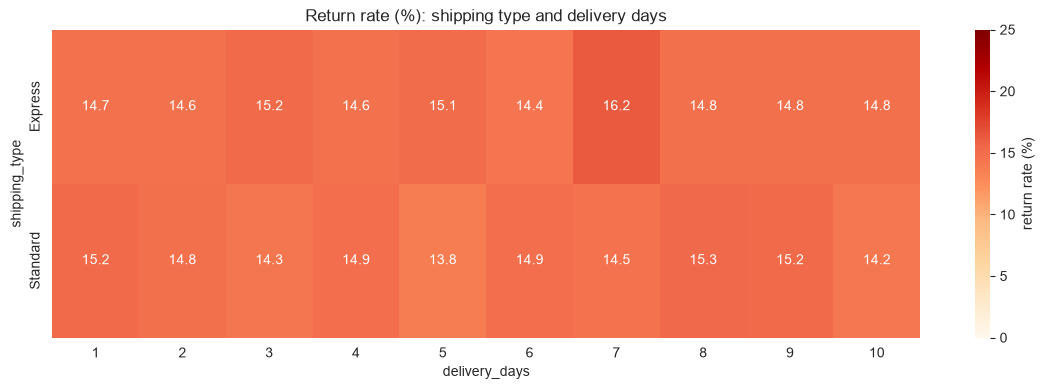

In [38]:
pivot_sd = retail_data.pivot_table(values="is_return", index="shipping_type", columns="delivery_days", aggfunc="mean") * 100
display(pivot_sd.round(1))

plt.figure(figsize=(14, 4))
sns.heatmap(pivot_sd, annot=True, fmt=".1f", cmap="OrRd", vmin=0, vmax=25, cbar_kws={"label": "return rate (%)"})
plt.title("Return rate (%): shipping type and delivery days")
plt.savefig("outputs/figures/19_shipping_delivery_return.png", bbox_inches="tight")
plt.show()

### 10.4 City and category: revenue

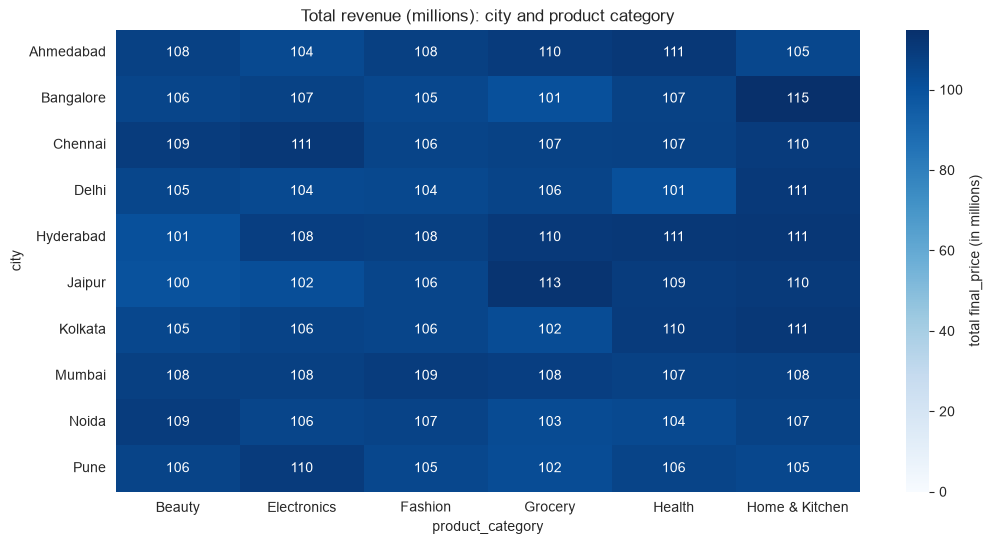

In [39]:
pivot_city = retail_data.pivot_table(values="final_price", index="city", columns="product_category", aggfunc="sum") / 1000000

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_city, annot=True, fmt=".0f", cmap="Blues", vmin=0, cbar_kws={"label": "total final_price (in millions)"})
plt.title("Total revenue (millions): city and product category")
plt.savefig("outputs/figures/20_city_category_revenue.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* **Category, discount and price:** in every category the average final price goes down as the discount band goes up, from about 73,000 to 74,500 in the 0-5% band to about 52,700 to 55,400 in the 26-30% band (around 26% lower). The categories are similar to each other in the same band. The highest value is Home & Kitchen with 0-5% discount (74,502), and Electronics with 11-15% discount is just 64,795. So I do not see that moderate discounts give the highest value. The order value is highest when the discount is lowest, because customers do not buy more when the discount is bigger (see 11.4).
* **Segment, age and spending:** all the averages are between 63,295 (Premium, 56-65) and 65,432 (Premium, 46-55), which is within about 2% of the overall average. Premium is highest in the 46-55 and 26-35 groups, but Premium 36-45 is normal (64,034). No segment leads in all age groups.
* **Shipping, delivery days and returns:** the return rate is between 13.8% (Standard, 5 days) and 16.2% (Express, 7 days), and it does not go up when the delivery days go up.
* **City and category:** every cell of the revenue heatmap is about 100 to 115 million, so no city is strong in only one category.

### 10.5 Pairplot and facet grid

The pairplot shows every numerical column against every other one, coloured by customer segment (a sample of 2,500 orders is used). The facet grid makes one chart for each customer segment.

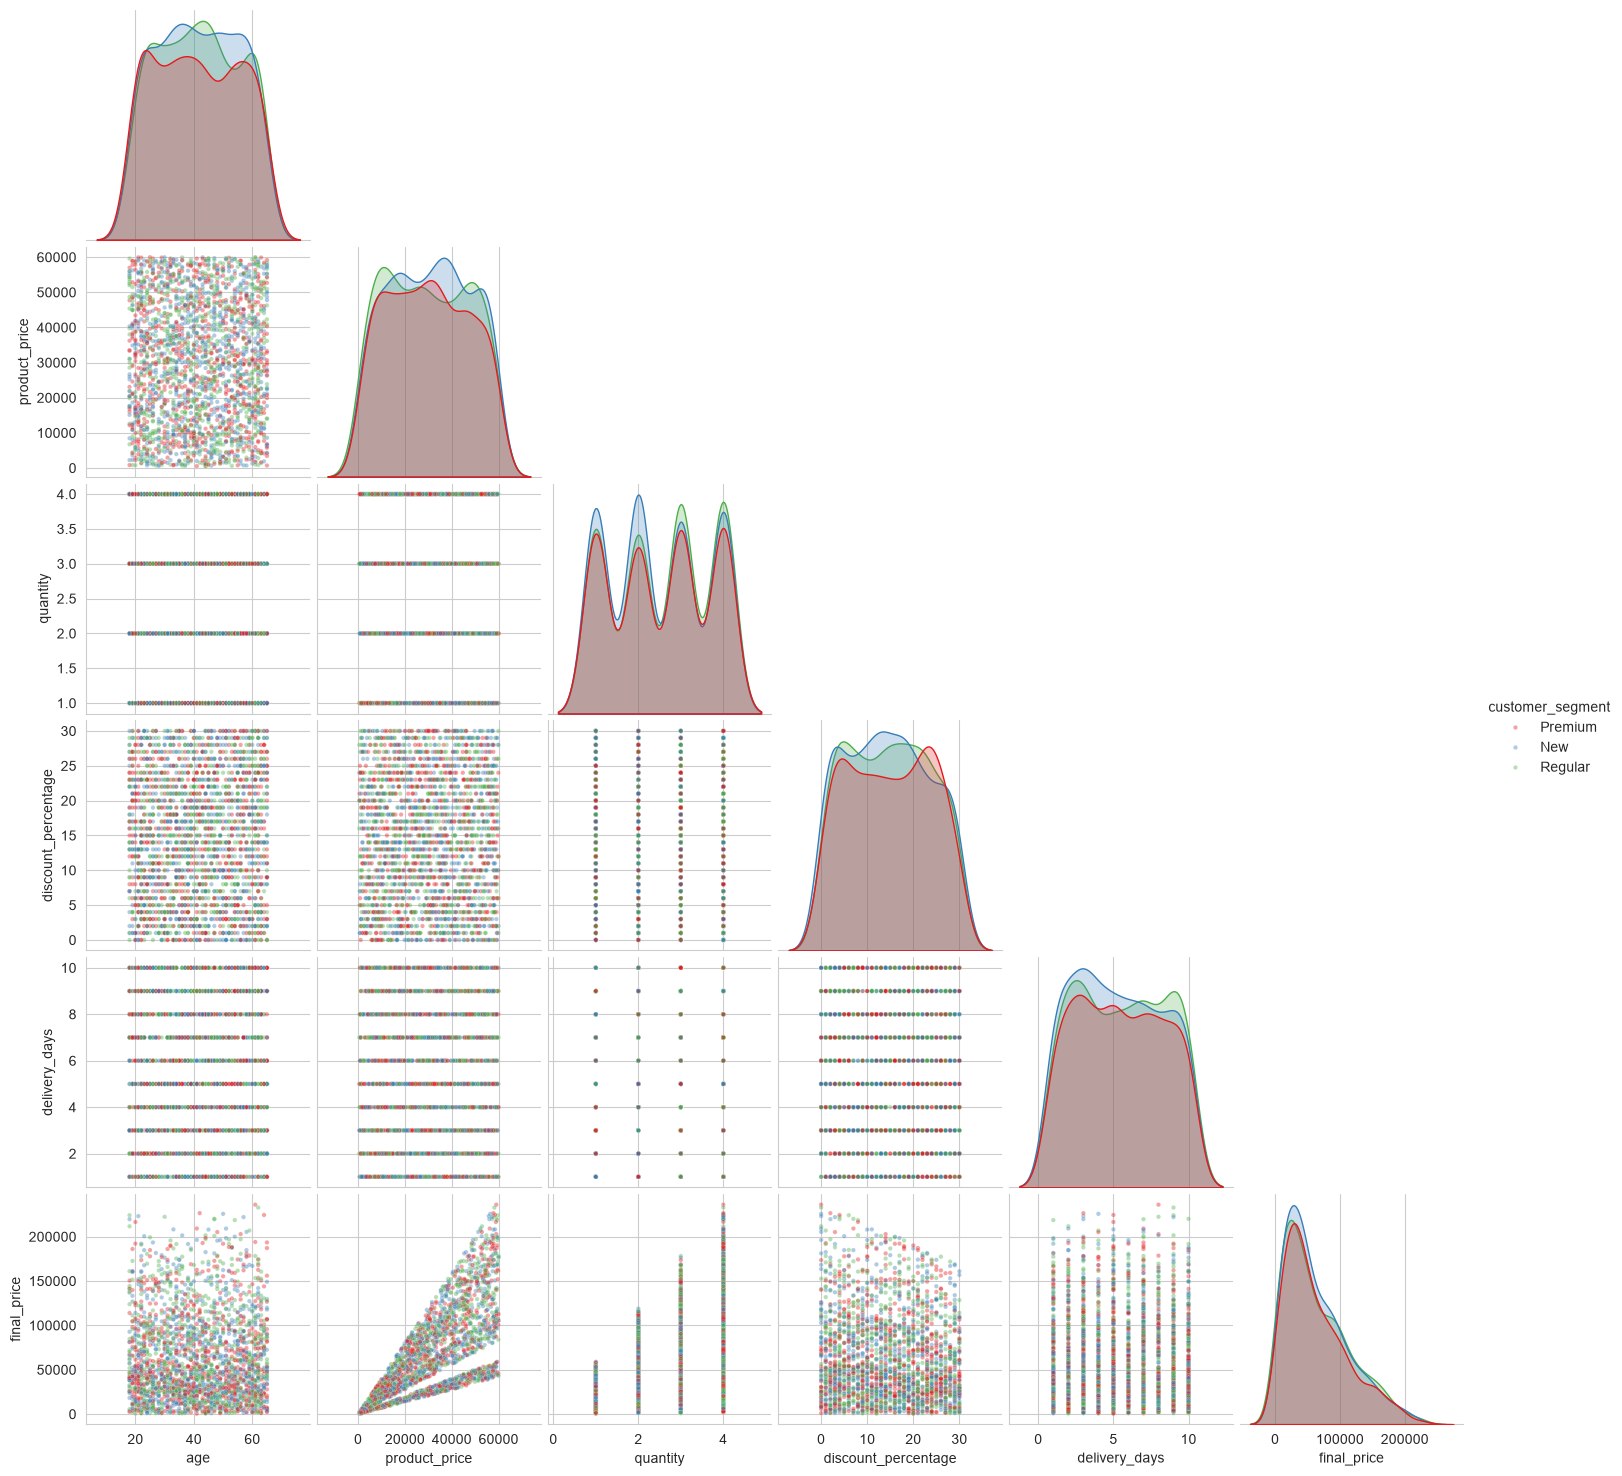

In [40]:
pairplot_columns = ["age", "product_price", "quantity", "discount_percentage", "delivery_days", "final_price"]
sns.pairplot(retail_data.sample(2500, random_state=1), vars=pairplot_columns, hue="customer_segment",
             palette="Set1", corner=True, plot_kws={"alpha": 0.4, "s": 10})
plt.savefig("outputs/figures/21_pairplot.png", bbox_inches="tight")
plt.show()

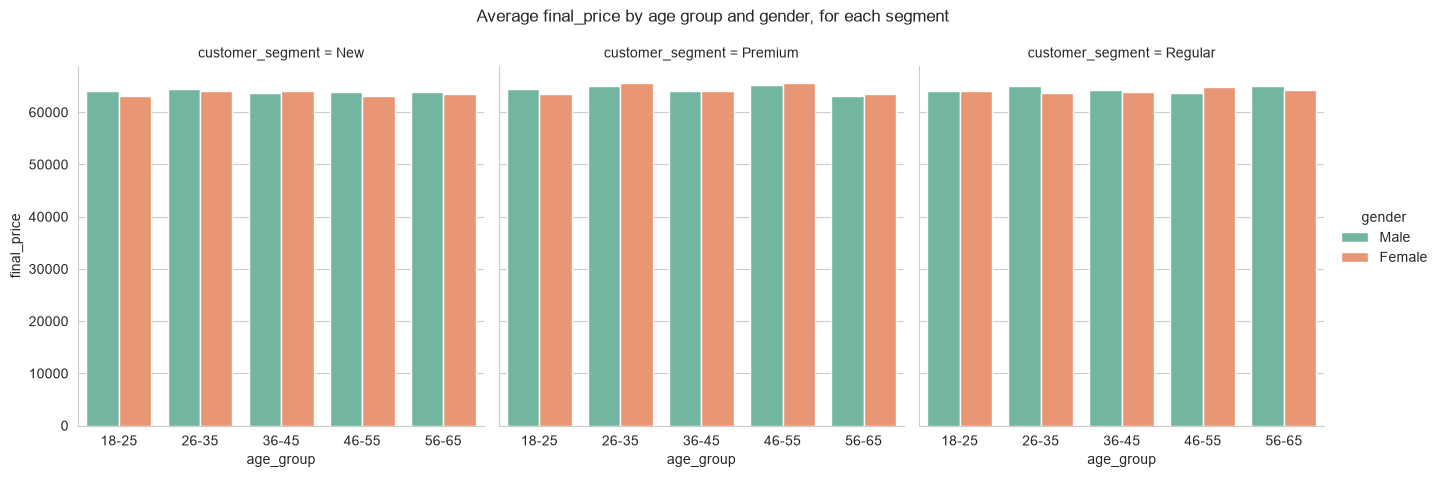

In [41]:
grid = sns.catplot(data=retail_data, x="age_group", y="final_price", hue="gender", col="customer_segment",
                   kind="bar", palette="Set2", errorbar=None, height=4.5)
grid.figure.suptitle("Average final_price by age group and gender, for each segment", y=1.05)
plt.savefig("outputs/figures/22_facet_grid.png", bbox_inches="tight")
plt.show()

### 10.6 Are the independent columns related to each other?

The columns age, product_price, quantity, discount_percentage and delivery_days are the inputs. If they were strongly related to each other (multicollinearity) it would be a problem for models. `final_price` is left out because it is calculated from them.

In [42]:
input_columns = ["age", "product_price", "quantity", "discount_percentage", "delivery_days"]
retail_data[input_columns].corr().round(3)

,age,product_price,quantity,discount_percentage,delivery_days
age,1.00,-0.00,-0.00,-0.00,-0.00
product_price,-0.00,1.00,0.00,-0.00,0.00
quantity,-0.00,0.00,1.00,-0.00,0.00
discount_percentage,-0.00,-0.00,-0.00,1.00,-0.00
delivery_days,-0.00,0.00,0.00,-0.00,1.00


**Interpretation:**

* In the pairplot, age, price, quantity, discount and delivery days against each other are just evenly filled dots with no pattern. Only the `final_price` row shows a pattern (it goes up with price and quantity and down with discount, which is the formula). The three segment colours overlap in every plot, so the segments behave in the same way.
* In the facet grid the bars of all age groups and both genders are at about the same height (around 64,000) in all three segment charts.
* The correlations between the input columns are all 0.00, so there is no multicollinearity problem among them.

## 11. Extra Analysis (beyond the assignment)

**Objective:** The brief only lists a few comparisons, but the data can answer more questions. Here we look at how sales change over time, which cities and products bring more revenue, and what discounts really do.

### 11.1 Time: months, weekdays and years

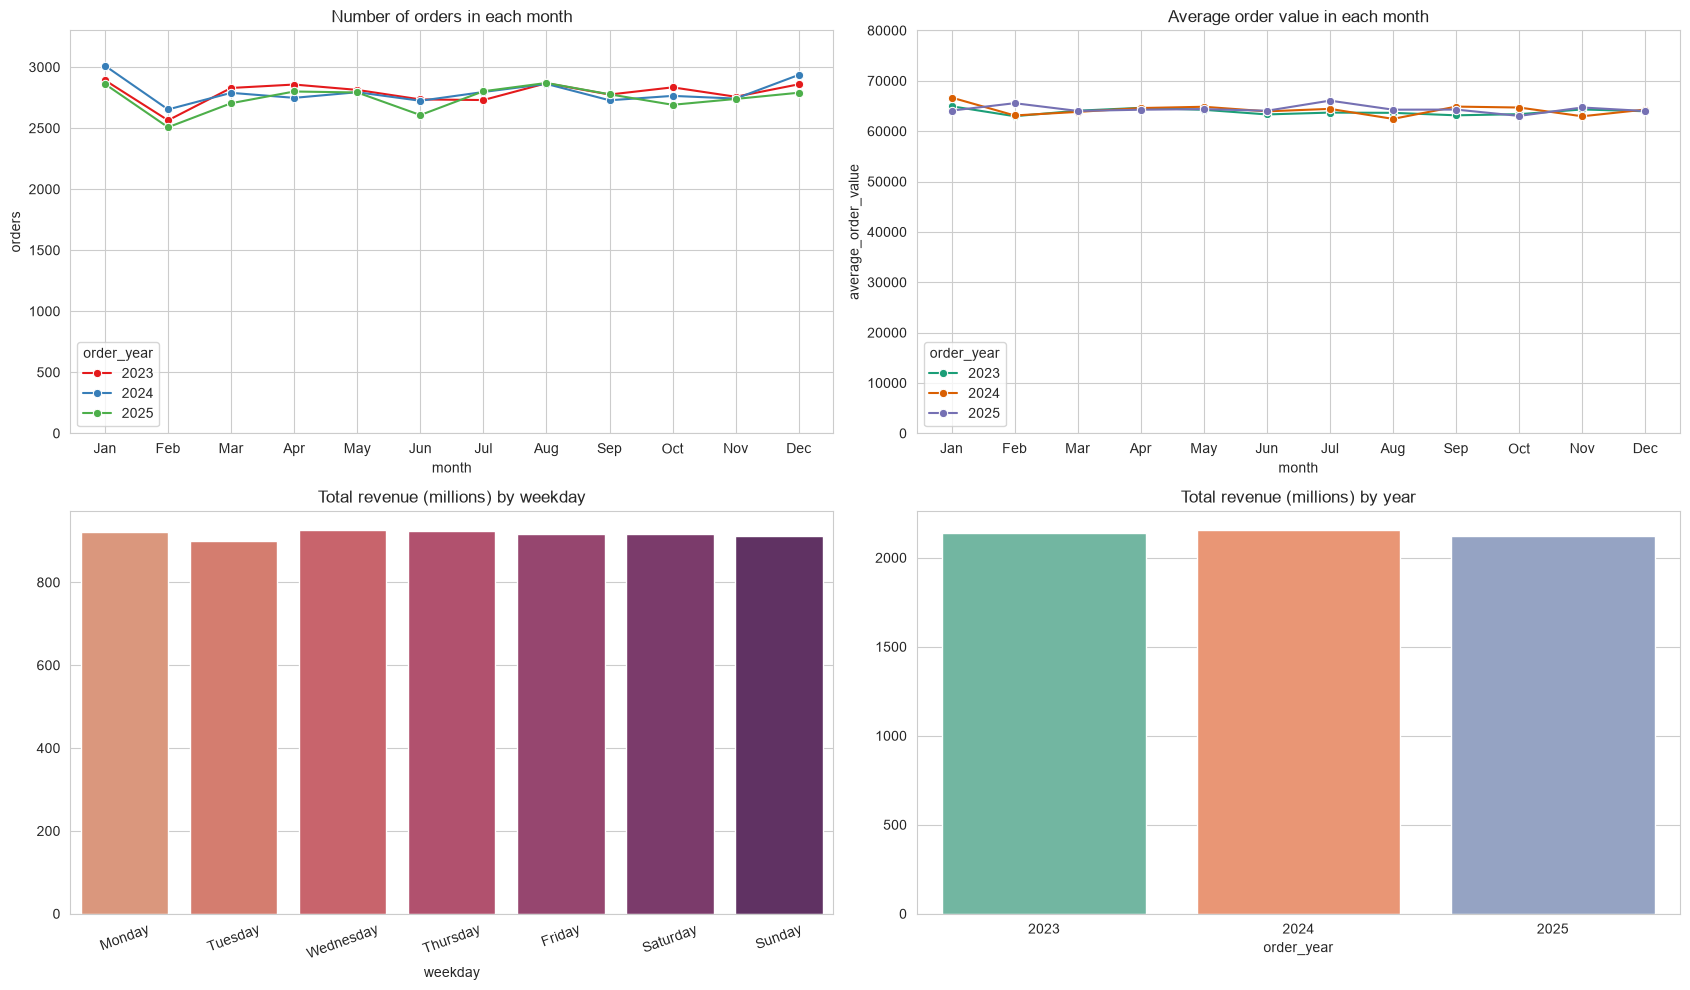

,orders,revenue,average_order_value,return_rate
order_year,,,,
2023,33513,"2,140,485,042.87","63,870.29",14.46
2024,33547,"2,155,130,180.21","64,242.11",15.00
2025,32940,"2,120,957,115.16","64,388.50",14.98


In [43]:
# orders and average order value for every month of every year
monthly = retail_data.groupby(["order_year", "order_month"]).agg(orders=("order_id", "count"),
                                                                 average_order_value=("final_price", "mean")).reset_index()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(2, 2, figsize=(17, 10))

sns.lineplot(data=monthly, x="order_month", y="orders", hue="order_year", palette="Set1", marker="o", ax=axes[0, 0])
axes[0, 0].set_title("Number of orders in each month")

sns.lineplot(data=monthly, x="order_month", y="average_order_value", hue="order_year", palette="Dark2", marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Average order value in each month")

weekday_revenue = retail_data.groupby("weekday")["final_price"].sum().reindex(weekday_order) / 1000000
sns.barplot(x=weekday_revenue.index, y=weekday_revenue.values, hue=weekday_revenue.index, palette="flare", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Total revenue (millions) by weekday")
axes[1, 0].tick_params(axis="x", rotation=20)

year_revenue = retail_data.groupby("order_year")["final_price"].sum() / 1000000
sns.barplot(x=year_revenue.index, y=year_revenue.values, hue=year_revenue.index, palette="Set2", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Total revenue (millions) by year")

for ax in (axes[0, 0], axes[0, 1]):
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.set_xlabel("month")
axes[0, 0].set_ylim(0, 3300)
axes[0, 1].set_ylim(0, 80000)

plt.tight_layout()
plt.savefig("outputs/figures/23_time_analysis.png", bbox_inches="tight")
plt.show()

yearly = retail_data.groupby("order_year").agg(orders=("order_id", "count"), revenue=("final_price", "sum"),
                                               average_order_value=("final_price", "mean"), return_rate=("is_return", "mean"))
yearly["return_rate"] = yearly["return_rate"] * 100
yearly

**Interpretation:**

* The three years are very similar. Orders were 33,513 (2023), 33,547 (2024) and 32,940 (2025). Revenue was 2,140 million, 2,155 million and 2,121 million. The average order value was 63,870, 64,242 and 64,389 and the return rate 14.5%, 15.0% and 15.0%. 2025 has about 1.6% less revenue than 2024, which is a small drop.
* The orders in each month are about 2,500 to 3,000. February is lower because it has fewer days, and January and December are a bit higher in some years. The average order value stays between about 62,000 and 67,000 in all months. The lines of the three years follow each other, so I do not see a clear growth, fall or seasonal pattern.
* The revenue on each weekday is about 900 to 925 million, so no day stands out.

### 11.2 Cities and states

,orders,revenue,average_order_value,return_rate
city,,,,
Chennai,9993,650.62,"65,107.98",15.12
Hyderabad,10150,650.43,"64,081.53",14.66
Mumbai,10015,648.85,"64,787.77",14.60
Ahmedabad,10057,644.68,"64,102.31",14.79
Bangalore,10047,640.95,"63,795.19",14.91
Kolkata,9955,639.98,"64,286.89",14.84
Jaipur,9920,639.65,"64,481.22",15.14
Noida,9964,635.89,"63,818.44",14.63
Pune,9937,634.23,"63,824.77",14.48


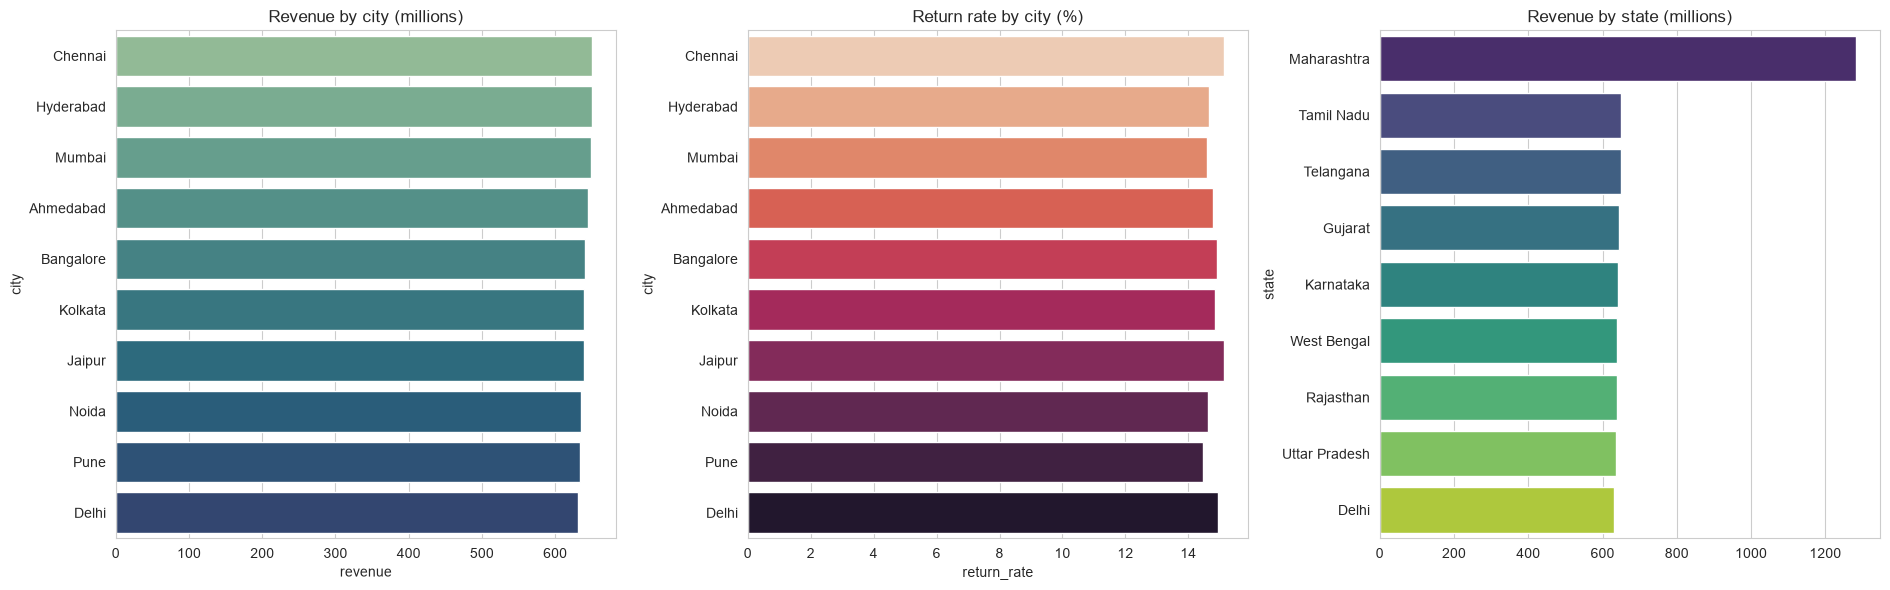

In [44]:
city_table = retail_data.groupby("city").agg(orders=("order_id", "count"), revenue=("final_price", "sum"),
                                             average_order_value=("final_price", "mean"), return_rate=("is_return", "mean"))
city_table["return_rate"] = city_table["return_rate"] * 100
city_table["revenue"] = city_table["revenue"] / 1000000
city_table = city_table.sort_values("revenue", ascending=False)
display(city_table)

state_revenue = retail_data.groupby("state")["final_price"].sum().sort_values(ascending=False) / 1000000

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
sns.barplot(x=city_table["revenue"], y=city_table.index, hue=city_table.index, palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Revenue by city (millions)")
sns.barplot(x=city_table["return_rate"], y=city_table.index, hue=city_table.index, palette="rocket_r", legend=False, ax=axes[1])
axes[1].set_title("Return rate by city (%)")
sns.barplot(x=state_revenue.values, y=state_revenue.index, hue=state_revenue.index, palette="viridis", legend=False, ax=axes[2])
axes[2].set_title("Revenue by state (millions)")

plt.tight_layout()
plt.savefig("outputs/figures/24_city_state.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* Every city gives about one tenth of the revenue, from 631 million (Delhi) to 651 million (Chennai). The average order value is from 63,371 (Delhi) to 65,108 (Chennai) and the return rate from 14.48% (Pune) to 15.14% (Jaipur). These gaps are small, and the tests in sections 8.5 and 9.4 also showed no real difference between cities.
* Maharashtra is the top state with about 1,283 million (20%) only because it has two cities, Mumbai and Pune. Per city it is the same as the others.
* So no city or state really stands out in revenue, order value or returns.

### 11.3 Products: subcategories and prices

,product_category,product_subcategory,orders,revenue,average_unit_price,return_rate
15,Health,Supplements,5657,359.90,"29,992.65",15.08
14,Health,Protein Powder,5668,359.82,"30,003.13",14.54
11,Grocery,Organic Rice,5567,357.44,"30,370.81",14.46
2,Beauty,Shampoo,5578,356.82,"30,217.22",15.24
0,Beauty,Face Cream,5512,354.04,"29,763.88",13.79
16,Health,Vitamins,5533,353.91,"30,424.21",14.87
13,Grocery,Snacks,5548,353.34,"29,825.04",15.23
12,Grocery,Pulses,5477,352.80,"30,118.82",14.92
1,Beauty,Perfume,5423,346.48,"30,193.68",15.25
3,Electronics,Headphones,4265,277.74,"31,102.62",14.28


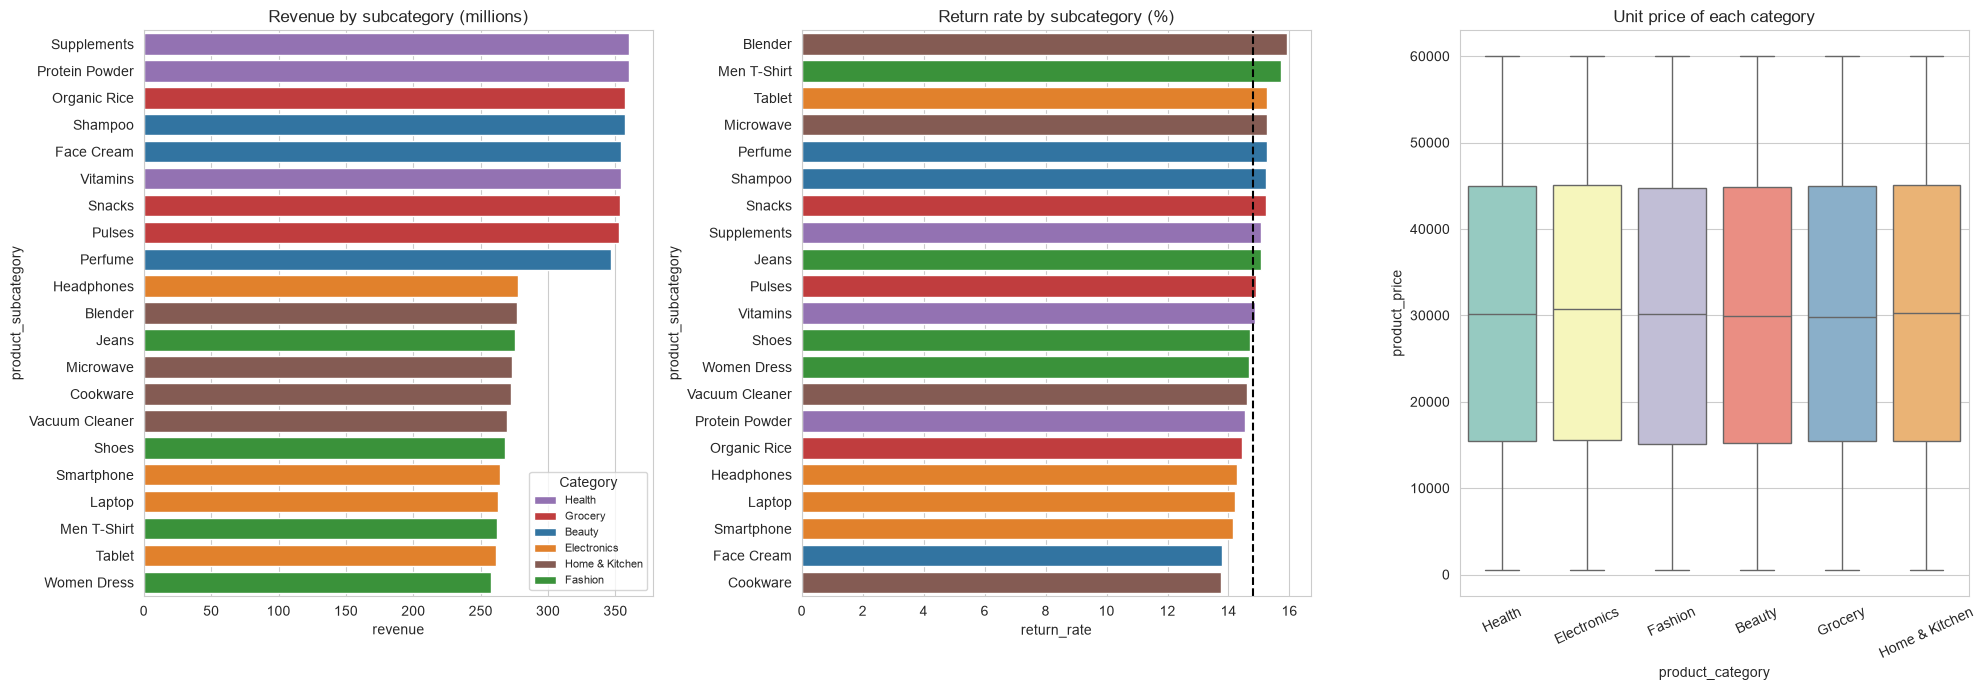

In [45]:
product_table = retail_data.groupby(["product_category", "product_subcategory"]).agg(
    orders=("order_id", "count"), revenue=("final_price", "sum"),
    average_unit_price=("product_price", "mean"), return_rate=("is_return", "mean")).reset_index()
product_table["revenue"] = product_table["revenue"] / 1000000
product_table["return_rate"] = product_table["return_rate"] * 100
product_table = product_table.sort_values("revenue", ascending=False)
display(product_table)

# same colour for the same category in all charts
categories = sorted(retail_data["product_category"].unique())
category_colors = dict(zip(categories, sns.color_palette("tab10", len(categories))))

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
sns.barplot(data=product_table, x="revenue", y="product_subcategory", hue="product_category",
            palette=category_colors, dodge=False, ax=axes[0])
axes[0].set_title("Revenue by subcategory (millions)")
axes[0].legend(title="Category", loc="lower right", fontsize=8)

by_return = product_table.sort_values("return_rate", ascending=False)
sns.barplot(data=by_return, x="return_rate", y="product_subcategory", hue="product_category",
            palette=category_colors, dodge=False, legend=False, ax=axes[1])
axes[1].axvline(retail_data["is_return"].mean() * 100, color="black", linestyle="--")
axes[1].set_title("Return rate by subcategory (%)")

sns.boxplot(data=retail_data, x="product_category", y="product_price", hue="product_category", palette="Set3", legend=False, ax=axes[2])
axes[2].set_title("Unit price of each category")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig("outputs/figures/25_products.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* The top subcategories by revenue are Supplements (359.9 million), Protein Powder (359.8), Organic Rice (357.4) and Shampoo (356.8). The lowest are Women Dress (257.4), Tablet (261.4) and Laptop (262.6). The top 9 all belong to Health, Grocery and Beauty, which have 3 subcategories each, and the rest belong to categories with 4. This is the same reason as in section 5: the same orders divided between fewer products. The order values are about the same.
* The return rate of the subcategories is between 13.75% (Cookware) and 15.91% (Blender), which is within chance as seen in section 9.
* The average unit price is between 29,764 and 31,103 for all 21 subcategories, and the boxplots of the six categories look the same. So a laptop or a smartphone has the same price range as snacks or pulses, which is not how a real shop works. This makes me think the data is made artificially, so I would not read too much into the product prices.

### 11.4 Discounts: do they make customers buy more?

The first discount band (0-5%) has six whole-number values and the others have five, so it has slightly more orders. Because of this, averages per order are compared instead of totals.

,orders,average_quantity,average_gross_order,average_final_price,average_discount_given,return_rate
discount_band,,,,,,
0-5%,19364,2.51,"75,535.88","73,663.40","1,872.48",14.82
6-10%,16063,2.50,"75,875.86","69,797.06","6,078.80",14.98
11-15%,16151,2.49,"75,225.37","65,423.21","9,802.15",14.84
16-20%,16133,2.51,"75,962.95","62,281.74","13,681.22",14.39
21-25%,16130,2.49,"75,093.46","57,822.95","17,270.51",14.66
26-30%,16159,2.50,"75,199.65","54,141.87","21,057.78",15.17


Total sales before discount (millions): 7548.4
Total discount given (millions): 1131.8 = 14.99 % of sales
Correlation between discount % and quantity: -0.0036


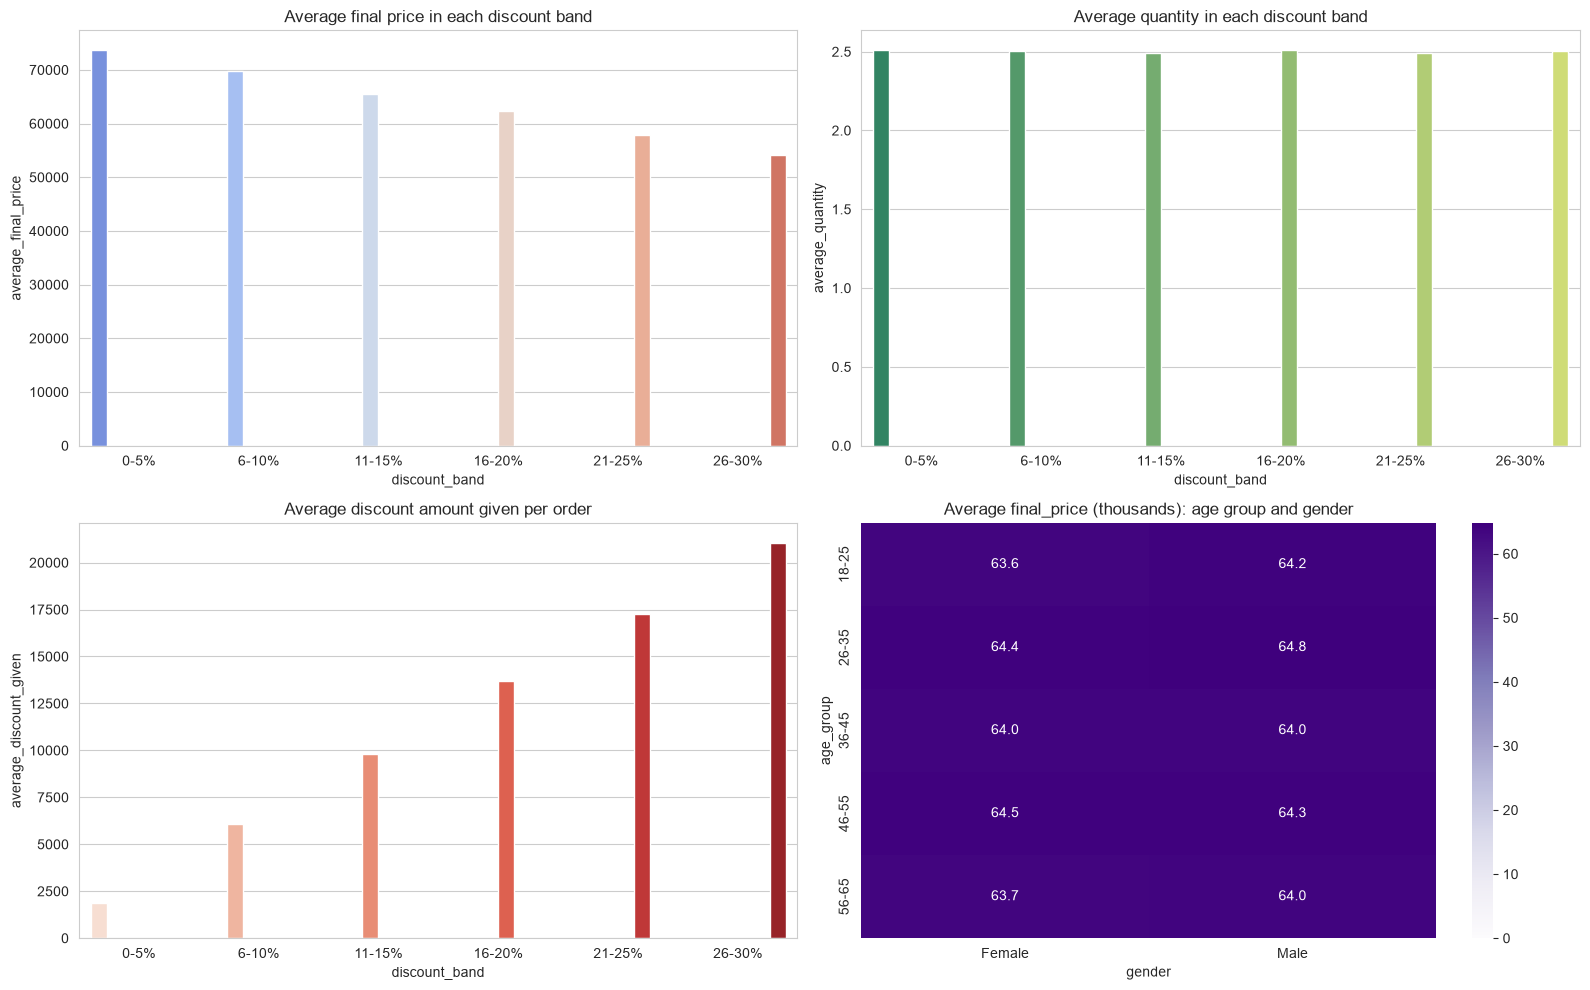

In [46]:
discount_table = retail_data.groupby("discount_band", observed=True).agg(
    orders=("order_id", "count"), average_quantity=("quantity", "mean"), average_gross_order=("gross_amount", "mean"),
    average_final_price=("final_price", "mean"), average_discount_given=("discount_amount", "mean"),
    return_rate=("is_return", "mean"))
discount_table["return_rate"] = discount_table["return_rate"] * 100
display(discount_table)

total_gross = retail_data["gross_amount"].sum()
total_discount = retail_data["discount_amount"].sum()
print("Total sales before discount (millions):", round(total_gross / 1000000, 1))
print("Total discount given (millions):", round(total_discount / 1000000, 1), "=", round(total_discount / total_gross * 100, 2), "% of sales")
print("Correlation between discount % and quantity:", round(retail_data["discount_percentage"].corr(retail_data["quantity"]), 4))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.barplot(data=discount_table.reset_index(), x="discount_band", y="average_final_price", hue="discount_band",
            palette="coolwarm", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Average final price in each discount band")
sns.barplot(data=discount_table.reset_index(), x="discount_band", y="average_quantity", hue="discount_band",
            palette="summer", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Average quantity in each discount band")
sns.barplot(data=discount_table.reset_index(), x="discount_band", y="average_discount_given", hue="discount_band",
            palette="Reds", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Average discount amount given per order")

pivot_ag = retail_data.pivot_table(values="final_price", index="age_group", columns="gender", aggfunc="mean", observed=True)
sns.heatmap(pivot_ag / 1000, annot=True, fmt=".1f", cmap="Purples", vmin=0, ax=axes[1, 1])
axes[1, 1].set_title("Average final_price (thousands): age group and gender")

plt.tight_layout()
plt.savefig("outputs/figures/26_discounts_age_gender.png", bbox_inches="tight")
plt.show()

**Interpretation:**

* The total sales before discount are 7,548.4 million, the discount given is 1,131.8 million (14.99% of sales) and the revenue after discount is 6,416.6 million.
* The discount did not make customers buy more. The average quantity is the same in every band (2.49 to 2.51) and the correlation between discount and quantity is -0.0036.
* The average final price falls from 73,663 in the 0-5% band to 54,142 in the 26-30% band (26.5% lower), and the average discount given per order goes from 1,872 to 21,058 (about 11 times). The return rate does not change much (14.4% to 15.2%).
* The 0-5% band has more orders (19,364 against about 16,100) only because it has six discount values, not because small discounts bring more orders.
* One limit: the data has only the orders that were placed. We cannot know if discounts bring new customers who would not have bought otherwise.
* In the age and gender heatmap every cell is between 63.6 and 64.8 thousand, so there is no real difference.

## 12. Final Findings and Conclusion

### 12.1 Quick numbers

In [47]:
quick_numbers = pd.Series({
    "Orders": f"{len(retail_data):,}",
    "Period": f"{retail_data['order_date'].min().date()} to {retail_data['order_date'].max().date()}",
    "Total revenue (millions)": f"{retail_data['final_price'].sum() / 1000000:,.1f}",
    "Average order value": f"{retail_data['final_price'].mean():,.0f}",
    "Median order value": f"{retail_data['final_price'].median():,.0f}",
    "Discount given (% of sales)": f"{retail_data['discount_amount'].sum() / retail_data['gross_amount'].sum() * 100:.2f}%",
    "Return rate": f"{retail_data['is_return'].mean() * 100:.2f}%",
    "Outlier orders in final_price": f"{retail_data['is_outlier'].sum():,}",
}, name="value").to_frame()
quick_numbers

,value
Orders,"100,000"
Period,2023-01-01 to 2025-12-30
Total revenue (millions),"6,416.6"
Average order value,"64,166"
Median order value,"49,752"
Discount given (% of sales),14.99%
Return rate,14.81%
Outlier orders in final_price,"1,335"


### 12.2 Main findings

1. The data is clean. There are no missing values, no duplicates and no spacing or spelling problems, and the value checks passed.
2. `final_price` is calculated from price, quantity and discount, so its strong correlation with them is expected.
3. Age, price, quantity, discount and delivery days are evenly spread. `final_price` is the only right-skewed column (skewness 0.93).
4. Only `final_price` has outliers, 1,335 orders (1.3%), and all of them have quantity 4 with a high price and a low discount. They are real orders. Capping them changes the average by only 0.3%.
5. Segment, gender, age, city, payment method and shipping type make no real difference to the order value (all p-values above 0.05).
6. The return rate is 14.81% and it is about the same in every group. None of the columns is related to returns.
7. Express shipping takes the same time as Standard (5.50 and 5.51 days).
8. Discounts cost about 15% of the sales, and customers did not buy more because of them. The order value is highest when the discount is lowest.
9. There is no clear trend or seasonality in the three years, and the cities, weekdays and subcategories are all similar.

### 12.3 Ideas from the brief: what this data shows

* **Matched:** the return rate is about 15% (14.81%), the discount is spread evenly from 0 to 30%, price and quantity are strongly related to `final_price`, and age is not related to spending.
* **Did not match:** `product_price` is not skewed, `final_price` does not have very high kurtosis, Regular is not the largest segment, Electronics does not have the most orders or the most returns, Express is not faster, Premium customers do not spend clearly more, moderate discounts do not give the highest value, and longer delivery does not increase returns.

### 12.4 Suggestions

* Check the discount policy. In this data the discounts did not increase the quantity, but they cost about 15% of the sales.
* Do not target customers by segment, gender, age or city using this data, because there is no difference between them.
* Look at the Express service. If customers pay more for it but get the delivery in the same time as Standard, something is wrong.
* The reason for returns is not in these columns, so it would help to collect the return reason.

### 12.5 Limitations

* The data looks artificially made. Most columns are perfectly flat, the prices do not depend on the product, and the input columns have zero correlation. Real data is usually not like this, so these results are for this dataset only.
* Each customer has only one order, so repeat purchases cannot be studied.
* There is no cost or profit column, so revenue is not the same as profit. The currency is also not given.
* The analysis shows relations, not reasons. For example we cannot know what customers would have done without the discount.

### 12.6 Conclusion

In this project the retail data was checked and cleaned, and then analysed with univariate, bivariate and multivariate methods, outlier detection with capping, correlation, a few simple statistical tests and some extra analysis of time, cities, products and discounts. The main result is that the order value depends on the price, quantity and discount of the order and not on who the customer is. The returns are about 15% everywhere and do not depend on any of the columns, and discounts reduced the revenue per order without increasing the quantity. Since the data looks artificial, the same analysis should be repeated on real data to see if the same patterns appear. The cleaned data (`data/Processed_dataset.csv`) and the charts (`outputs/figures/`) are saved for further work such as modelling.